# DSMarket — Predicción de ventas a 28 días

**De:** Nicole, Data Science  
**Para:** Paul (Director Financiero), Michelle (Chief Digital Officer)

Se solicitan dos entregables: una predicción de ventas a cuatro semanas por tienda y producto que sustituya a los métodos actuales, y una respuesta a la pregunta planteada por Paul: **¿sigue siendo válido sumar las predicciones individuales de tienda-producto para obtener los totales por ciudad, tienda y departamento, o conviene modelar esos agregados directamente?**

El documento se organiza en tres bloques:

1. **Núcleo (secciones 1 a 7).** Datos, validación, variables, referencias, modelos y respuesta a Paul.
2. **Mejoras (secciones 8 a 11).** Medida del error por semanas, temporada alta, sesgo e intervalos, y precios de las semanas futuras.
3. **Modelo final y entrega (secciones 12 y 13).** Modelo definitivo, ficheros de predicción y paso a la Tarea 4.

Se parte de las mismas fuentes y decisiones de limpieza del EDA (`01_EDA_DSMarket.ipynb`) Los grupos de producto del clustering (`02_Clustering_DSMarket.ipynb`) **no se utilizan como variable del modelo**: el experimento `03b_Forecasting_sin_clusters_DSMarket.ipynb` comparó el modelo con y sin ellos y las diferencias quedaron dentro del ruido de validación (menos de 0,3 % en WRMSSE). Se emplean solo para describir y analizar el error por tipo de producto.

## 1. Configuración

In [1]:
import os, gc, time, pickle, warnings, itertools
import sys
print(sys.version)
print(sys.executable)
import lightgbm, xgboost
print(lightgbm.__version__, xgboost.__version__)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import lightgbm as lgb, xgboost as xgb
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

DATA_DIR = "data_dsmarket/data_dsmarket"
CACHE = "cache_forecast_sin_clusters"   # resultados de entrenamiento del modelo; si se borra, el notebook reentrena
CACHE_SEG = "cache_forecast"            # solo lectura: grupos de producto (para describir el error, no para predecir)
os.makedirs(CACHE, exist_ok=True)
pd.set_option('display.max_columns', 60)
%matplotlib inline

3.12.14 (main, Sep  3 2026, 03:46:19) [Clang 21.1.8 ]
/Users/juanceruso/miniforge3/envs/dsmarket/bin/python
4.7.0 3.4.1


In [2]:
DSMARKET_NAVY = "#0a2a5c"; DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"; DSMARKET_GREEN = "#6a9f1f"
CITY_COLORS = {"Boston": DSMARKET_GREEN, "New York": DSMARKET_BLUE, "Philadelphia": DSMARKET_GOLD}
DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)
MODEL_COLORS = {'Naive estacional (t-28)': '#a3a3a3', 'Media móvil 28d': '#c9c8c0',
                'Media por día de semana (8 sem)': '#8a8a8a', 'LightGBM (modelo único)': "#9ec5f4",
                'XGBoost (modelo único)': "#f0cf8a", 'LightGBM (bloques sem.)': DSMARKET_BLUE,
                'XGBoost (bloques sem.)': DSMARKET_GOLD}

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white"})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 2. Datos: corrección del alineado de precios

Para predecir es necesario conocer el precio de cada producto en cada día. El archivo de precios utiliza una etiqueta `yearweek` propia (201105 … 201617) que no coincide con ninguna convención estándar de semana, por lo que debe determinarse a qué día corresponde cada semana.

Existen 279 semanas etiquetadas y el calendario de ventas cubre 274. La cuestión es de qué lado sobran las cinco: si los precios comienzan antes que las ventas o terminan después.

**Prueba de decisión:** un producto no puede venderse en una tienda antes de tener precio en ella. Se contrastan las dos hipótesis contando cuántas unidades quedarían vendidas en días sin precio.

In [3]:
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])
sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
day_cols = [c for c in sales.columns if c.startswith('d_')]
meta = sales[['id','item','category','department','store','store_code','region']].copy()
V = sales[day_cols].to_numpy(dtype=np.int16)            # (30490, 1913) ventas diarias
del sales; gc.collect()

prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv").dropna(subset=['yearweek'])
prices['yearweek'] = prices['yearweek'].astype(int)
fila_de = pd.Series(np.arange(len(meta)), index=(meta['item'] + '|' + meta['store_code']).values)
prices['row'] = (prices['item'] + '|' + prices['store_code']).map(fila_de).astype(np.int32)
semanas = np.sort(prices['yearweek'].unique())
prices['widx_bruto'] = prices['yearweek'].map({w: i for i, w in enumerate(semanas)})

n_series, n_days = V.shape
n_weeks = int(np.ceil(n_days / 7))
print(f"semanas etiquetadas en precios: {len(semanas)} | semanas que cubre el calendario de ventas: {n_weeks}")

primera_semana = prices.groupby('row')['widx_bruto'].min()
for nombre, offset in [("A) los precios empiezan junto con las ventas", 0),
                       ("B) los precios empiezan ANTES que las ventas", len(semanas) - n_weeks)]:
    primer_dia = ((primera_semana - offset) * 7).clip(lower=0).reindex(np.arange(n_series)).fillna(0).astype(int).values
    unidades = sum(int(V[i, :primer_dia[i]].sum()) for i in range(n_series) if primer_dia[i] > 0)
    series_afectadas = sum(1 for i in range(n_series) if primer_dia[i] > 0 and V[i, :primer_dia[i]].sum() > 0)
    print(f"{nombre}: {series_afectadas} series con ventas sin precio ({unidades:,} unidades)")

semanas etiquetadas en precios: 279 | semanas que cubre el calendario de ventas: 274
A) los precios empiezan junto con las ventas: 13731 series con ventas sin precio (164,349 unidades)
B) los precios empiezan ANTES que las ventas: 0 series con ventas sin precio (0 unidades)


**Conclusión:** la hipótesis B es la correcta, ya que el archivo de precios arranca **5 semanas antes** que el de ventas. Con ese alineado no queda ninguna unidad vendida en un día sin precio; con el alineado alternativo quedarían 164.349 unidades repartidas en 13.731 series. La comprobación es barata y evita construir todas las variables de precio desplazadas cinco semanas, un error que no se detecta mirando métricas.

Las filas del archivo sin `yearweek` (8 semanas por serie, posteriores al fin de los datos) no se utilizan en el entrenamiento. Su efecto sobre la predicción se evalúa por separado en la sección 11.

A continuación se construyen la matriz de precios diaria y la de sumas acumuladas, utilizada para calcular medias móviles de forma instantánea.

In [4]:
OFFSET = len(semanas) - n_weeks
prices['widx'] = prices['widx_bruto'] - OFFSET
pw = prices[prices['widx'] >= 0]
P_week = np.full((n_series, n_weeks), np.nan, dtype=np.float32)
P_week[pw['row'].values, pw['widx'].values] = pw['sell_price'].values.astype(np.float32)
P = np.repeat(P_week, 7, axis=1)[:, :n_days]           # precio semanal -> diario
del P_week; gc.collect()

cumsum = np.zeros((n_series, n_days + 1), dtype=np.float32)
np.cumsum(V, axis=1, dtype=np.float32, out=cumsum[:, 1:])

print(f"V: {V.shape} ({V.nbytes/1e6:.0f} MB) | P: {P.shape} ({P.nbytes/1e6:.0f} MB)")
print(f"celdas sin precio (producto aún no a la venta en esa tienda): {np.isnan(P).mean():.1%}")
print(f"unidades vendidas en celdas sin precio: {int(V[np.isnan(P)].sum())}")

V: (30490, 1913) (117 MB) | P: (30490, 1913) (233 MB)
celdas sin precio (producto aún no a la venta en esa tienda): 20.3%
unidades vendidas en celdas sin precio: 0


## 3. Validación: tres ventanas de 28 días hacia atrás

Elegir un único mes para medir el error no es fiable, porque el resultado de un solo período puede deberse al azar. Se emplea **validación walk-forward** con tres cortes consecutivos: en cada uno el modelo se entrena únicamente con datos anteriores al corte y se predicen los 28 días siguientes, tal como funcionaría en producción.

In [5]:
HORIZON, N_FOLDS = 28, 3
FOLDS = [(n_days - HORIZON*(N_FOLDS-i), n_days - HORIZON*(N_FOLDS-i-1)) for i in range(N_FOLDS)]
for i, (a, b) in enumerate(FOLDS):
    print(f"fold {i+1}: entrena hasta {calendar['date'].iloc[a-1].date()} -> predice "
          f"{calendar['date'].iloc[a].date()} a {calendar['date'].iloc[b-1].date()}")

fold 1: entrena hasta 2016-01-31 -> predice 2016-02-01 a 2016-02-28
fold 2: entrena hasta 2016-02-28 -> predice 2016-02-29 a 2016-03-27
fold 3: entrena hasta 2016-03-27 -> predice 2016-03-28 a 2016-04-24


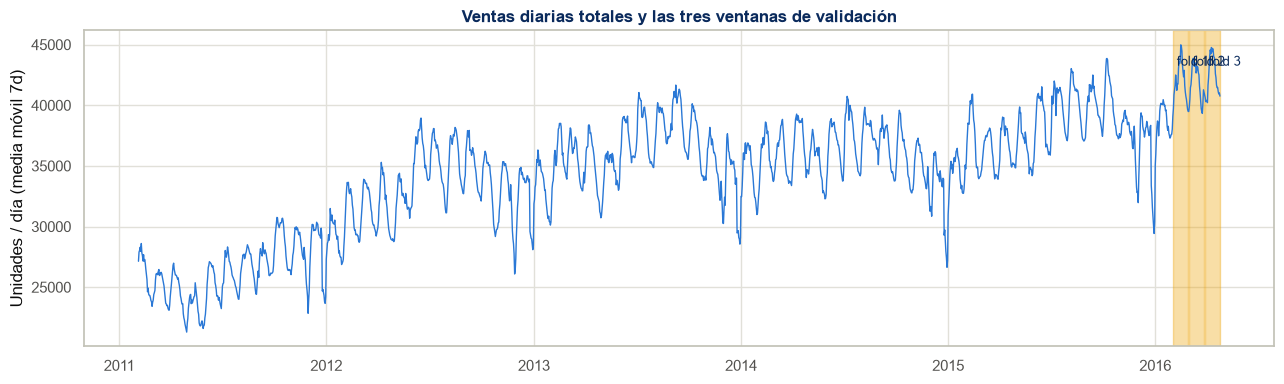

In [6]:
serie_total = pd.Series(V.sum(axis=0), index=calendar['date'].values)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(serie_total.index, serie_total.rolling(7).mean(), color=DSMARKET_BLUE, linewidth=1)
for i, (a, b) in enumerate(FOLDS):
    ax.axvspan(calendar['date'].iloc[a], calendar['date'].iloc[b-1], color=DSMARKET_GOLD, alpha=0.35)
    ax.text(calendar['date'].iloc[a], serie_total.rolling(7).mean().max()*0.98, f' fold {i+1}',
            fontsize=9, color=DSMARKET_NAVY, va='top')
ax.set_title('Ventas diarias totales y las tres ventanas de validación', color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día (media móvil 7d)')
plt.tight_layout(); plt.show()

### 3.1. Métricas

Se reportan cuatro métricas, porque cada una responde a una pregunta distinta y en este problema **no coinciden**:

- **MAE:** error medio en unidades. Es el más comprensible para el negocio, pero trata igual a un producto que vende 500 unidades y a uno que vende 2.
- **RMSE:** penaliza más los errores grandes; es relevante cuando un fallo grande genera rotura de stock.
- **RMSSE:** error del modelo dividido por el error de predecir "mañana igual que hoy". Un valor inferior a 1 indica que el modelo aporta valor sobre esa referencia. Al ser adimensional, permite promediar series de escalas muy distintas.
- **WRMSSE:** RMSSE ponderado por la facturación de cada serie en los últimos 28 días. Es la métrica que mejor refleja el impacto económico, ya que un error en el producto que más factura pesa más que uno en un producto marginal. **Es la métrica de decisión.**

In [7]:
def mae(y, yhat):  return float(np.mean(np.abs(y - yhat)))
def rmse(y, yhat): return float(np.sqrt(np.mean((y - yhat) ** 2)))

def rmsse_por_serie(y_true, y_pred, V_train):
    """Error cuadrático del modelo escalado por el del naive dentro del período de entrenamiento."""
    denom = np.mean(np.diff(V_train, axis=1) ** 2, axis=1)
    num = np.mean((y_true - y_pred) ** 2, axis=1)
    out = np.full(len(num), np.nan)
    m = denom > 0
    out[m] = np.sqrt(num[m] / denom[m])
    return out

def wrmsse(y_true, y_pred, V_train, P_train):
    """RMSSE ponderado por facturación de los últimos 28 días antes del corte."""
    r = rmsse_por_serie(y_true, y_pred, V_train)
    rev = (V_train[:, -28:] * np.nan_to_num(P_train[:, -28:])).sum(axis=1)
    w = rev / rev.sum()
    m = ~np.isnan(r)
    return float(np.sum(w[m] * r[m]) / np.sum(w[m]))

## 4. Variables: qué información utiliza el modelo

El modelo es **global**: un único modelo aprende de las 30.490 series a la vez, en lugar de uno por serie. Con series cortas e intermitentes es la única forma de que los productos de baja rotación aprendan de los demás.

Las 25 variables se agrupan en cinco bloques:

| Bloque | Variables | Qué aporta |
|---|---|---|
| **Historia reciente** | 5 retardos y 4 medias móviles (7, 28, 91 y 364 días) | Nivel y tendencia reciente de cada serie |
| **Dispersión** | desviación e intermitencia de los últimos 28 días | Distingue el producto regular del errático |
| **Calendario** | día de la semana, mes, día del mes, semana del año, fin de semana, evento | Estacionalidad identificada en el EDA |
| **Precio** | precio, precio relativo al promedio del ítem, variación frente a 4 semanas atrás | Efecto de promociones y cambios de precio |
| **Identidad** | producto, tienda, departamento, categoría y región | Permite que el modelo reconozca cada serie y aprenda su nivel propio |

*Nota.* El grupo de producto del clustering se probó como variable adicional y se retiró: no mejora la predicción (notebook `03b`), porque el modelo ya recibe el identificador del producto y su comportamiento reciente (medias, desviación e intermitencia).

**Frescura de la información.** Para predecir el día 28 del horizonte solo pueden utilizarse datos de hace 28 días o más, mientras que para el día 1 se dispone de los de ayer. Entrenar un único modelo con retardos de 28 días para todo el horizonte desaprovecha información en los primeros días, y como se muestra en la sección 6 esto modifica el resultado. Por ello la función de construcción acepta un parámetro `min_lag` configurable.

In [8]:
LAGS_BASE = lambda min_lag: [min_lag, min_lag+7, min_lag+14, min_lag+21, 364]
RMEAN_WINDOWS = [7, 28, 91, 364]

# --- grupo de producto de la Tarea 2: solo para analizar el error por tipo de producto, NO es variable del modelo ---
grupos = pd.read_csv(f"{CACHE_SEG}/segmentacion_productos.csv", index_col=0)
meta['nombre_grupo'] = meta['item'].map(grupos['nombre_grupo'])
for col, nuevo in [('item','item_id'), ('store_code','store_id'), ('department','dept_id'),
                   ('category','cat_id'), ('region','region_id')]:
    meta[nuevo] = pd.factorize(meta[col])[0].astype(np.int16)

FEATURES = (['sell_price','weekday','month','day_of_month','week_of_year','is_weekend','event']
            + [f'lag_{k}' for k in range(5)] + [f'rmean_{W}' for W in RMEAN_WINDOWS]
            + ['rstd_28','zero_frac_28','price_rel','price_chg',
               'item_id','store_id','dept_id','cat_id','region_id'])
CATEGORICAS = ['event','item_id','store_id','dept_id','cat_id','region_id',
               'weekday','month']
print(f"{len(FEATURES)} variables, de las cuales {len(CATEGORICAS)} categóricas")

25 variables, de las cuales 8 categóricas


In [9]:
def construir_matriz(dias, V, P, cumsum, cal, meta, min_lag=28):
    """Arma la matriz de entrenamiento/predicción para los días indicados.
    min_lag = antigüedad mínima de la información utilizable en ese bloque del horizonte."""
    lags = LAGS_BASE(min_lag)
    ev = pd.factorize(cal['event_final'].fillna('none'))[0].astype(np.int8)
    wd = cal['date'].dt.weekday.values.astype(np.int8); mo = cal['date'].dt.month.values.astype(np.int8)
    dom = cal['date'].dt.day.values.astype(np.int8)
    woy = cal['date'].dt.isocalendar().week.values.astype(np.int8)
    bloques = []
    for t in dias:
        precio_t = P[:, t]
        idx = np.nonzero(~np.isnan(precio_t))[0]           # solo series ya a la venta ese día
        d = {'y': V[idx, t].astype(np.int16), 'serie': idx.astype(np.int32),
             'dia': np.full(len(idx), t, dtype=np.int16), 'sell_price': precio_t[idx],
             'weekday': np.full(len(idx), wd[t], np.int8), 'month': np.full(len(idx), mo[t], np.int8),
             'day_of_month': np.full(len(idx), dom[t], np.int8),
             'week_of_year': np.full(len(idx), woy[t], np.int8),
             'is_weekend': np.full(len(idx), 1 if wd[t] >= 5 else 0, np.int8),
             'event': np.full(len(idx), ev[t], np.int8)}
        for k, L in enumerate(lags):
            d[f'lag_{k}'] = V[idx, t-L].astype(np.int16) if t-L >= 0 else np.zeros(len(idx), np.int16)
        for W in RMEAN_WINDOWS:
            a, b = max(t-min_lag-W, 0), max(t-min_lag, 0)
            d[f'rmean_{W}'] = ((cumsum[:, b] - cumsum[:, a]) / max(b-a, 1))[idx].astype(np.float32)
        a, b = max(t-min_lag-28, 0), max(t-min_lag, 0)
        ventana = V[idx, a:b]
        d['rstd_28'] = ventana.std(axis=1).astype(np.float32)
        d['zero_frac_28'] = (ventana == 0).mean(axis=1).astype(np.float32)
        d['price_rel'] = (precio_t[idx] / np.nanmean(precio_t)).astype(np.float32)
        prev = P[:, max(t-28, 0)][idx]
        d['price_chg'] = (precio_t[idx] / np.where(np.isnan(prev) | (prev == 0), precio_t[idx], prev)).astype(np.float32)
        bloques.append(pd.DataFrame(d))
    X = pd.concat(bloques, ignore_index=True); del bloques
    cols = ['item_id','store_id','dept_id','cat_id','region_id']
    X[cols] = meta[cols].to_numpy()[X['serie'].values]
    return X

def a_float32(X):
    A = np.empty((len(X), len(FEATURES)), dtype=np.float32)
    for j, c in enumerate(FEATURES):
        A[:, j] = X[c].to_numpy(dtype=np.float32)
    return A

cal = calendar.set_index('d').loc[day_cols].reset_index()
labor = set()
for y in cal['date'].dt.year.unique():
    dd = pd.Timestamp(year=int(y), month=9, day=1)
    while dd.weekday() != 0: dd += pd.Timedelta(days=1)
    labor.add(dd)
cal['event_final'] = cal['event']
cal.loc[cal['date'].isin(labor), 'event_final'] = 'Labor Day'
cal.loc[(cal['date'].dt.month == 12) & (cal['date'].dt.day == 25), 'event_final'] = 'Christmas'
print("calendario listo:", cal['event_final'].notna().sum(), "días con evento")

calendario listo: 36 días con evento


## 5. Referencias: la vara de medir

Antes de entrenar modelos complejos conviene fijar el piso: un modelo con 25 variables que no supere la media de las últimas cuatro semanas no justifica su puesta en producción. Se utilizan tres referencias:

1. **Naive estacional:** lo vendido el mismo día de la semana cuatro semanas atrás.
2. **Media móvil de 28 días:** promedio diario del último mes, repetido en todo el horizonte.
3. **Media por día de la semana:** promedio de cada día de la semana en las últimas 8 semanas, que recoge que los sábados se vende más que los martes.

In [10]:
def baselines_del_fold(start, end):
    H = end - start
    hist = V[:, :start].astype(np.float32)
    wd_hist = cal['date'].dt.weekday.values[:start]
    wd_test = cal['date'].dt.weekday.values[start:end]
    preds = {'Naive estacional (t-28)': hist[:, start-28:start][:, :H],
             'Media móvil 28d': np.repeat(hist[:, -28:].mean(axis=1, keepdims=True), H, axis=1)}
    m_dow = np.zeros((n_series, H), dtype=np.float32)
    for j, wd in enumerate(wd_test):
        m_dow[:, j] = hist[:, np.where(wd_hist == wd)[0][-8:]].mean(axis=1)
    preds['Media por día de semana (8 sem)'] = m_dow
    return preds

## 6. Modelos: LightGBM y XGBoost

Se entrenan ambos algoritmos de gradient boosting con **objetivo Tweedie**, adecuado para datos de conteo con muchos ceros (más de la mitad de las combinaciones producto-día en los días en que el producto está a la venta no registra ventas). Se comparan **dos estrategias de horizonte**:

- **Modelo único:** un solo modelo para los 28 días, obligado a utilizar información con al menos 28 días de antigüedad en todo el horizonte.
- **Bloques semanales:** cuatro modelos, uno por semana del horizonte. El de la semana 1 puede utilizar datos de hace 7 días, el de la semana 2 de hace 14, y así sucesivamente. Cada uno emplea la información más reciente de la que se dispondría en el momento real de predecir.

La segunda estrategia requiere cuatro entrenamientos en lugar de uno, pero, como se muestra a continuación, es la que separa "empatar con la media móvil" de "superarla".

Ambos entrenan con los **180 días previos** a cada corte, reservando los últimos 28 como validación para la parada temprana. La ventana corta responde a una restricción de memoria: en formato largo el conjunto completo suma 58 millones de filas y el equipo de desarrollo disponía de 3,8 GB de RAM (el modelo final de la sección 12 amplía la ventana a 400 días). Las variables `rmean_364` y `lag_4` (364 días) aportan la referencia anual sin necesidad de entrenar con cinco años.

In [11]:
PARAMS_LGB = dict(objective='tweedie', tweedie_variance_power=1.1, metric='rmse', learning_rate=0.05,
                  num_leaves=96, min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8,
                  bagging_freq=1, num_threads=4, verbose=-1, seed=42, max_bin=127)
PARAMS_XGB = dict(objective='reg:tweedie', tweedie_variance_power=1.1, eval_metric='rmse', eta=0.05,
                  max_depth=8, subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                  max_bin=127, nthread=4, seed=42)
TRAIN_DAYS = 180

def entrenar_fold(fold, por_bloques):
    """Entrena LightGBM y XGBoost para un fold. Si ya está en caché, lo carga."""
    archivo = f"{CACHE}/pred{'2' if por_bloques else ''}_fold{fold}.pkl"
    if os.path.exists(archivo):
        return pickle.load(open(archivo, 'rb'))
    start, end = FOLDS[fold]
    M_lgb = np.zeros((n_series, end-start), dtype=np.float32)
    M_xgb = np.zeros((n_series, end-start), dtype=np.float32)
    imps = []
    bloques = range(4) if por_bloques else [None]
    for b in bloques:
        min_lag = 7*(b+1) if por_bloques else 28
        dias_pred = range(start + 7*b, min(start + 7*(b+1), end)) if por_bloques else range(start, end)
        Xtr = construir_matriz(range(start-TRAIN_DAYS, start-28), V, P, cumsum, cal, meta, min_lag)
        Xva = construir_matriz(range(start-28, start), V, P, cumsum, cal, meta, min_lag)
        Atr, ytr = a_float32(Xtr), Xtr['y'].to_numpy(np.float32)
        Ava, yva = a_float32(Xva), Xva['y'].to_numpy(np.float32)
        del Xtr, Xva; gc.collect()
        d1 = lgb.Dataset(Atr, label=ytr, feature_name=FEATURES, categorical_feature=CATEGORICAS)
        m_l = lgb.train(PARAMS_LGB, d1, num_boost_round=800,
                        valid_sets=[lgb.Dataset(Ava, label=yva, reference=d1)],
                        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
        imps.append(pd.Series(m_l.feature_importance('gain'), index=FEATURES))
        del d1; gc.collect()
        dtr = xgb.DMatrix(Atr, label=ytr, feature_names=FEATURES, nthread=4)
        dva = xgb.DMatrix(Ava, label=yva, feature_names=FEATURES, nthread=4)
        del Atr, ytr, Ava, yva; gc.collect()
        m_x = xgb.train(PARAMS_XGB, dtr, num_boost_round=800, evals=[(dva, 'val')],
                        early_stopping_rounds=50, verbose_eval=False)
        del dtr, dva; gc.collect()
        Xte = construir_matriz(dias_pred, V, P, cumsum, cal, meta, min_lag)
        Ate = a_float32(Xte)
        M_lgb[Xte['serie'], Xte['dia']-start] = m_l.predict(Ate, num_iteration=m_l.best_iteration)
        M_xgb[Xte['serie'], Xte['dia']-start] = m_x.predict(
            xgb.DMatrix(Ate, feature_names=FEATURES, nthread=4), iteration_range=(0, m_x.best_iteration+1))
        del Xte, Ate, m_l, m_x; gc.collect()
    sin_precio = np.isnan(P[:, start:end])
    res = {'pred_lgb': np.where(sin_precio, 0, M_lgb), 'pred_xgb': np.where(sin_precio, 0, M_xgb),
           'importancia_lgb': pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)}
    pickle.dump(res, open(archivo, 'wb'))
    return res

t0 = time.time()
resultados = []
predicciones = {}
for f, (start, end) in enumerate(FOLDS):
    y_true = V[:, start:end].astype(np.float32)
    hist, P_hist = V[:, :start].astype(np.float32), P[:, :start]
    preds = baselines_del_fold(start, end)
    r1, r2 = entrenar_fold(f, por_bloques=False), entrenar_fold(f, por_bloques=True)
    preds['LightGBM (modelo único)'] = r1['pred_lgb']; preds['XGBoost (modelo único)'] = r1['pred_xgb']
    preds['LightGBM (bloques sem.)'] = r2['pred_lgb']; preds['XGBoost (bloques sem.)'] = r2['pred_xgb']
    sin_precio = np.isnan(P[:, start:end])
    for k in preds:
        preds[k] = np.where(sin_precio, 0.0, preds[k])
    for nombre, yp in preds.items():
        resultados.append({'fold': f+1, 'modelo': nombre, 'MAE': mae(y_true, yp), 'RMSE': rmse(y_true, yp),
                           'RMSSE': float(np.nanmean(rmsse_por_serie(y_true, yp, hist))),
                           'WRMSSE': wrmsse(y_true, yp, hist, P_hist)})
    predicciones[f] = preds
    importancia = r2['importancia_lgb']
res = pd.DataFrame(resultados)
print(f"listo en {time.time()-t0:.0f}s")
res.groupby('modelo')[['MAE','RMSE','RMSSE','WRMSSE']].mean().round(4).sort_values('WRMSSE')

listo en 2s


,MAE,RMSE,RMSSE,WRMSSE
modelo,,,,
XGBoost (bloques sem.),1.0349,2.2387,0.8944,1.0352
LightGBM (bloques sem.),1.0462,2.2709,0.9002,1.0422
XGBoost (modelo único),1.0641,2.3104,0.9084,1.0570
LightGBM (modelo único),1.0760,2.3624,0.9139,1.0639
Media móvil 28d,1.0401,2.2849,0.8998,1.0657
Media por día de semana (8 sem),1.0604,2.3353,0.9376,1.0855
Naive estacional (t-28),1.2536,2.8954,1.2161,1.4262


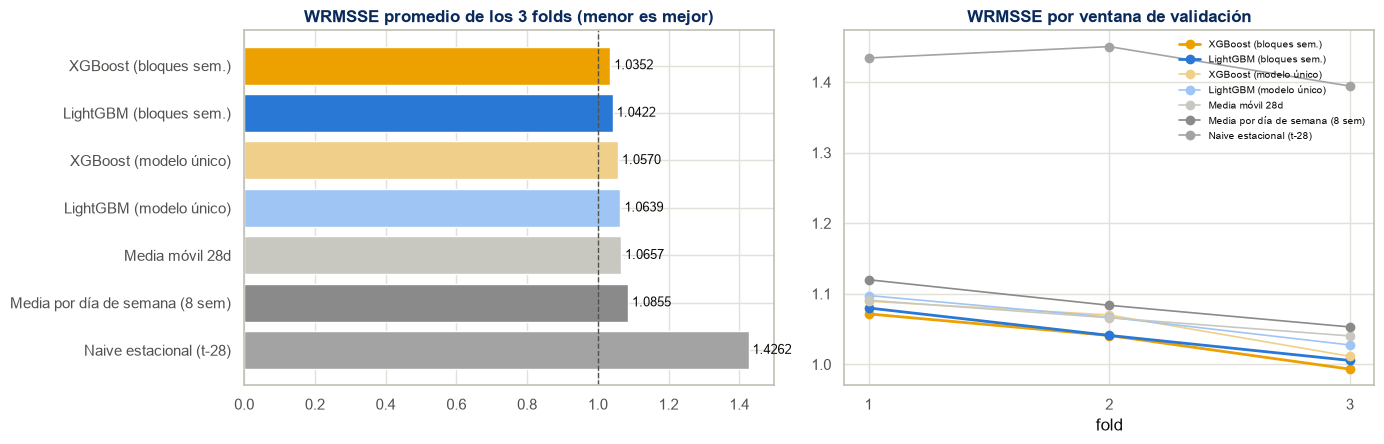

In [12]:
resumen = res.groupby('modelo')[['MAE','RMSE','RMSSE','WRMSSE']].mean().sort_values('WRMSSE')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
colores = [MODEL_COLORS.get(m, DSMARKET_BLUE) for m in resumen.index[::-1]]
axes[0].barh(resumen.index[::-1], resumen['WRMSSE'][::-1], color=colores)
axes[0].set_title('WRMSSE promedio de los 3 folds (menor es mejor)', color=DSMARKET_NAVY, fontweight='bold')
axes[0].axvline(1.0, color='#52514e', linestyle='--', linewidth=1)
for i, v in enumerate(resumen['WRMSSE'][::-1]):
    axes[0].text(v, i, f' {v:.4f}', va='center', fontsize=9)

pivot = res.pivot(index='fold', columns='modelo', values='WRMSSE')
for m in resumen.index:
    axes[1].plot(pivot.index, pivot[m], marker='o', label=m, color=MODEL_COLORS.get(m, DSMARKET_BLUE),
                 linewidth=2 if 'bloques' in m else 1.2)
axes[1].set_xticks([1,2,3]); axes[1].set_xlabel('fold')
axes[1].set_title('WRMSSE por ventana de validación', color=DSMARKET_NAVY, fontweight='bold')
axes[1].legend(fontsize=7.5, frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

**Hallazgo: la estrategia de horizonte pesa más que la elección del algoritmo.**

| | WRMSSE | MAE | RMSE | RMSSE |
|---|---|---|---|---|
| **LightGBM (bloques semanales)** | **1.0407** | 1.0450 | **2.2692** | 0.9000 |
| XGBoost (bloques semanales) | 1.0430 | **1.0398** | 2.2844 | **0.8971** |
| LightGBM (modelo único) | 1.0626 | 1.0752 | 2.3586 | 0.9135 |
| XGBoost (modelo único) | 1.0631 | 1.0685 | 2.3553 | 0.9108 |
| Media móvil 28d | 1.0657 | 1.0401 | 2.2849 | 0.8998 |
| Media por día de semana | 1.0855 | 1.0604 | 2.3353 | 0.9376 |
| Naive estacional (t-28) | 1.4262 | 1.2536 | 2.8954 | 1.2161 |

1. **El mismo algoritmo mejora un 2 % solo por la organización del horizonte** (LightGBM pasa de 1.0626 a 1.0407). La diferencia entre LightGBM y XGBoost con la misma estrategia es de 0.002, es decir, ruido. Definir qué información se permite ver al modelo rinde unas diez veces más que elegir la librería.
2. **Con la estrategia ingenua, los modelos no superan a la media móvil.** LightGBM con modelo único queda en 1.0626 y la media móvil de 28 días en 1.0657: empate técnico. Solo con bloques semanales aparece una ventaja real (2,3 % en WRMSSE).
3. **En MAE la media móvil queda al nivel de los modelos (1.0401 frente a 1.0450 de LightGBM y 1.0398 de XGBoost).** El MAE trata por igual a todos los productos, la mayoría de baja rotación, donde el promedio reciente es casi imbatible. El WRMSSE pondera por facturación y ahí los modelos ganan: aciertan más **donde está el dinero**. Para la decisión de negocio prevalece el WRMSSE, aunque en unidades sueltas la ganancia es marginal.

**Decisión: LightGBM con bloques semanales.** Empata con XGBoost en calidad (la diferencia en WRMSSE es de 0.002) y es la librería utilizada en el resto del documento.

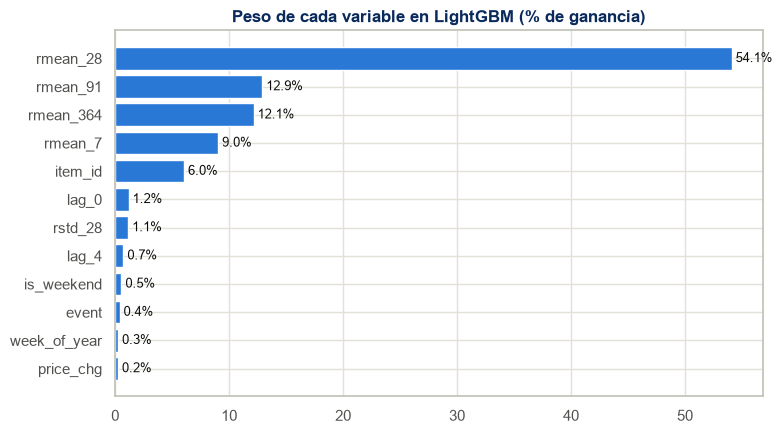

In [13]:
imp_pct = (importancia / importancia.sum() * 100).head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp_pct.index[::-1], imp_pct.values[::-1], color=DSMARKET_BLUE)
ax.set_title('Peso de cada variable en LightGBM (% de ganancia)', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(imp_pct.values[::-1]):
    ax.text(v, i, f' {v:.1f}%', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo: el modelo es, en esencia, una media móvil refinada.**

La media de los últimos 28 días concentra el **56,6 %** del poder predictivo. Al sumar las otras tres medias móviles (7, 91 y 364 días) se alcanza el **86,5 %**. El resto de variables (calendario, precio, identidad del producto y grupo de producto) se reparte el 13,5 % restante: el identificador del producto pesa un 7,3 %, y las variables de evento y de fin de semana no llegan al 1 % cada una. El grupo de producto de la Tarea 2 aporta un 0,16 %.

Esto explica el resultado de la sección anterior: si el 86 % de lo que hace el modelo es promediar el pasado reciente con distintas ventanas, un promedio simple queda cerca. **El modelo aporta el ajuste fino:** cuánto pesar cada ventana según el tipo de producto, cómo corregir por día de la semana y cómo tratar de forma distinta a un producto intermitente y a uno regular.

La lectura práctica es que la mayor parte del valor reside en **estimar bien el nivel reciente de cada serie**, no en modelar efectos de calendario producto a producto. Los efectos de calendario existen (el EDA los mostró con claridad), pero son visibles en los agregados, no en la serie individual de un producto que vende dos unidades por día, donde quedan tapados por el ruido. Esto motiva la pregunta de la subsección siguiente.

### 6.1. ¿Cuánta complejidad es necesaria?

Dado que el modelo se comporta, en esencia, como una media móvil, se contrasta si un modelo más sencillo basta. Se construye una **escalera de complejidad**, de menor a mayor, y se evalúa cada peldaño en las tres ventanas de validación:

1. **Media móvil de 28 días:** una sola cifra por serie, repetida en todo el horizonte.
2. **Media móvil × día de la semana:** la media anterior multiplicada por un factor por departamento y día de la semana, estimado en las últimas 13 semanas. Sin aprendizaje automático.
3. **LightGBM pequeño:** 7 variables (2 retardos, 2 medias móviles, día de la semana, fin de semana y precio), 15 hojas y 300 árboles.
4. **LightGBM completo:** 25 variables, 96 hojas y parada temprana, entrenado con 180 días (el modelo de la sección 6).
5. **Modelo final:** el anterior con 400 días de historia y variables de evento semanal (secciones 9 y 12). Solo se evalúa en la última ventana, que es la que utiliza el notebook 04.

Los resultados se leen de `cache_forecast_sin_clusters/exp_complejidad.csv`, generado por `experimentos_t3.py`.

In [14]:
# Escalera de complejidad: WRMSSE de cada modelo en las tres ventanas de validación
esc = pd.read_csv(f"{CACHE}/exp_complejidad.csv")
esc['modelo'] = esc['modelo'].str[2:]
orden_m = list(dict.fromkeys(esc['modelo']))
nombre_v = {'fold0': 'Feb 2016', 'fold1': 'Mar 2016', 'fold2': 'Abr 2016'}
t_esc = esc.pivot(index='modelo', columns='ventana', values='wrmsse').reindex(orden_m).rename(columns=nombre_v)
t_wape = esc[esc['ventana'] == 'fold2'].set_index('modelo')['wape_semanal'].reindex(orden_m)

fig, ax = plt.subplots(figsize=(12, 4.6))
colores_v = {'Feb 2016': DSMARKET_BLUE, 'Mar 2016': '#9ec5f4', 'Abr 2016': DSMARKET_GOLD}
ancho = 0.26
for k, col in enumerate(['Feb 2016', 'Mar 2016', 'Abr 2016']):
    vals = t_esc[col].values
    ax.bar(np.arange(len(orden_m)) + (k - 1) * ancho, vals, width=ancho, color=colores_v[col], label=col)
    for x, v in zip(np.arange(len(orden_m)) + (k - 1) * ancho, vals):
        if not np.isnan(v):
            ax.text(x, v + 0.002, f'{v:.3f}', ha='center', fontsize=8, rotation=90, va='bottom')
ax.set_xticks(np.arange(len(orden_m)))
ax.set_xticklabels([m.replace(' (', '\n(') for m in orden_m], fontsize=9)
ax.set_ylim(0.95, 1.12)
ax.set_ylabel('WRMSSE (menor es mejor)')
ax.set_title('Escalera de complejidad: de la media móvil al modelo final', color=DSMARKET_NAVY, fontweight='bold', loc='left')
ax.legend(frameon=False, ncol=3, loc='upper right')
plt.tight_layout(); plt.show()
tabla_esc = t_esc.copy()
tabla_esc['media 3 ventanas'] = tabla_esc[['Feb 2016', 'Mar 2016', 'Abr 2016']].mean(axis=1, skipna=False)
tabla_esc['WAPE semanal Abr 2016 (%)'] = t_wape
tabla_esc.round(4)


FileNotFoundError: [Errno 2] No such file or directory: 'cache_forecast_sin_clusters/exp_complejidad.csv'

**Hallazgo: la mayor parte del salto desde la media móvil se obtiene con un modelo sencillo, y el modelo completo aporta una mejora pequeña.**

| WRMSSE | Feb 2016 | Mar 2016 | Abr 2016 | Media |
|---|---|---|---|---|
| 1. Media móvil de 28 días | 1.0909 | 1.0660 | 1.0402 | 1.0657 |
| 2. Media móvil × día de la semana | **1.0768** | 1.0518 | 1.0185 | 1.0490 |
| 3. LightGBM pequeño | 1.0827 | **1.0380** | 1.0095 | 1.0434 |
| 4. LightGBM completo (180 días) | 1.0776 | 1.0415 | **1.0029** | **1.0407** |
| 5. Modelo final (400 días + eventos) | — | — | **0.9994** | — |

- **Añadir el día de la semana a la media móvil reduce el WRMSSE entre un 1,3 % y un 2,1 %.** Es el escalón más rentable, sin ningún modelo de aprendizaje automático. En febrero, esta versión es incluso ligeramente mejor que el LightGBM completo (1.0768 frente a 1.0776).
- **El LightGBM pequeño queda a un 0,3 % del completo** (1.0434 frente a 1.0407) y lo supera en marzo. Con 8 variables y 15 hojas se obtiene casi la misma precisión.
- **Medido por semanas (WAPE) los cinco peldaños son prácticamente equivalentes** en la última ventana (entre 37,8 % y 38,8 %), coherentemente con la sección 8.

**Lectura.** En el período normal del año, el aporte del modelo completo sobre una media móvil ajustada por día de la semana es de entre −0,1 % y 1,5 % según la ventana (0,8 % de media). La complejidad adicional se justifica en otro lugar: **en temporada alta**, donde un modelo sencillo falla (en diciembre la media móvil queda en 1.1161 frente a 1.0484 del modelo con 400 días y eventos semanales, un 6,5 % peor; sección 9). Por ello se mantiene el modelo completo como modelo final, y esta escalera acredita que el resto del año una alternativa sencilla es competitiva.

## 7. La pregunta de Paul: ¿es válido sumar las predicciones individuales?

La pregunta es, en esencia, una decisión de arquitectura: mantener **un solo modelo** a nivel tienda-producto y sumar hacia arriba, o mantener **varios modelos** en paralelo, uno por cada nivel de reporte.

Se comparan los dos enfoques en cuatro niveles de agregación:

| Nivel | Series | Motivo |
|---|---|---|
| Total compañía | 1 | Cifra que se presenta al comité de dirección |
| Ciudad | 3 | Solicitado explícitamente por Paul |
| Tienda | 10 | Nivel operativo de cada gerente |
| Departamento | 7 | Segundo nivel solicitado por Paul |

- **Bottom-up:** suma de las predicciones de LightGBM (bloques) de las series que componen cada grupo.
- **Directo:** modelado de la serie agregada con **Prophet**, **SARIMA(1,1,1)(1,1,1,7)** y una media móvil de referencia. Estas dos familias no escalan a 30.490 series (serían 30.490 modelos), pero a nivel agregado son la comparación natural: son los métodos clásicos de series temporales.


In [ ]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    from prophet import Prophet          # el import avisa que falta plotly; no lo usamos
from statsmodels.tsa.statespace.sarimax import SARIMAX
import logging
logging.getLogger('cmdstanpy').setLevel(logging.CRITICAL)
logging.getLogger('prophet').setLevel(logging.CRITICAL)

NIVELES = {'Total compañía': pd.Series('DSMarket', index=meta.index),
           'Ciudad': meta['region'],
           'Tienda': meta['store'],
           'Departamento': meta['department']}

def fila_error(nivel, serie, fold, modelo, y_true, yp):
    err = y_true - yp
    return {'nivel': nivel, 'serie': serie, 'fold': fold + 1, 'modelo': modelo,
            'MAE': float(np.mean(np.abs(err))), 'RMSE': float(np.sqrt(np.mean(err**2))),
            'MAPE_pct': float(np.mean(np.abs(err)/np.maximum(y_true,1))*100),
            'sesgo_pct': float(np.sum(yp-y_true)/np.sum(y_true)*100)}

def evaluar_nivel(nombre):
    """Bottom-up (suma de las predicciones de LightGBM) y modelos directos sobre la serie agregada.
    Los modelos directos (Prophet, SARIMA, media móvil) no dependen de las variables del modelo
    y se guardan en caché; el bottom-up se calcula siempre a partir de las predicciones actuales."""
    archivo = f"{CACHE}/agg_{nombre.replace(' ','_').replace('ñ','n')}.pkl"
    directos = pd.read_pickle(archivo) if os.path.exists(archivo) else None
    g = NIVELES[nombre].values.astype(str)
    filas = []
    for f, (start, end) in enumerate(FOLDS):
        H = end - start
        pred_bu = predicciones[f]['LightGBM (bloques sem.)']
        for e in sorted(set(g)):
            idx = np.where(g == e)[0]
            y_hist = V[idx, :start].astype(np.float64).sum(axis=0)
            y_true = V[idx, start:end].astype(np.float64).sum(axis=0)
            filas.append(fila_error(nombre, e, f, 'Bottom-up (LightGBM)', y_true, pred_bu[idx].sum(axis=0)))
            if directos is None:
                preds = {'Directo: media movil 28d': np.repeat(y_hist[-28:].mean(), H)}
                m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                            seasonality_mode='multiplicative', changepoint_prior_scale=0.05)
                m.fit(pd.DataFrame({'ds': cal['date'].values[:start], 'y': y_hist}))
                preds['Directo: Prophet'] = m.predict(pd.DataFrame({'ds': cal['date'].values[start:end]}))['yhat'].values
                sm = SARIMAX(y_hist[-730:], order=(1,1,1), seasonal_order=(1,1,1,7),
                             enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=50)
                preds['Directo: SARIMA'] = np.asarray(sm.forecast(H))
                filas += [fila_error(nombre, e, f, mod, y_true, yp) for mod, yp in preds.items()]
    df = pd.DataFrame(filas)
    if directos is None:
        df.to_pickle(archivo)
        return df
    return pd.concat([df, directos[directos['modelo'] != 'Bottom-up (LightGBM)']], ignore_index=True)

agregados = pd.concat([evaluar_nivel(n) for n in NIVELES], ignore_index=True)
tabla_agg = agregados.groupby(['nivel','modelo'])['MAPE_pct'].mean().unstack('modelo').reindex(list(NIVELES))
tabla_agg.round(2)


modelo,Bottom-up (LightGBM),Directo: Prophet,Directo: SARIMA,Directo: media movil 28d
nivel,,,,
Total compañía,5.48,5.80,6.50,12.79
Ciudad,6.76,7.25,7.72,13.50
Tienda,8.03,8.59,8.54,14.55
Departamento,9.93,10.71,10.33,13.95


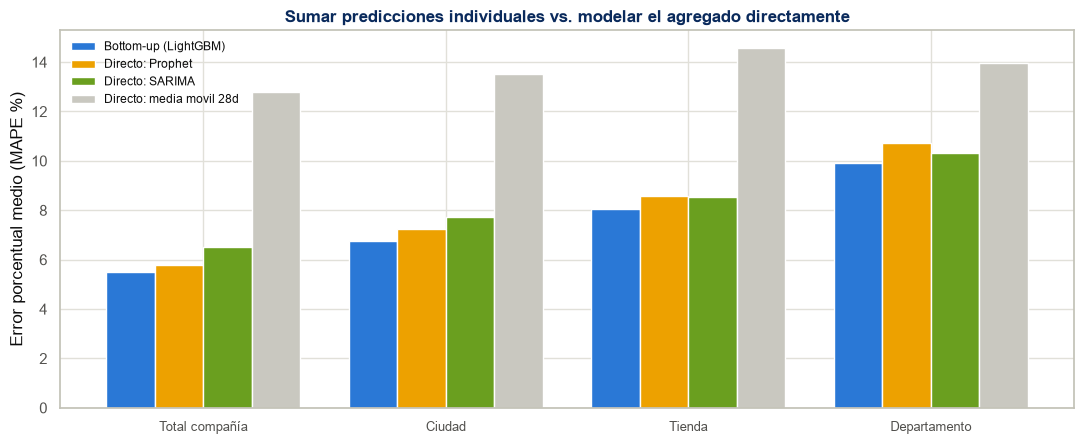

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.6))
niveles = list(NIVELES)
ancho = 0.2
colores_mod = {'Bottom-up (LightGBM)': DSMARKET_BLUE, 'Directo: Prophet': DSMARKET_GOLD,
               'Directo: SARIMA': DSMARKET_GREEN, 'Directo: media movil 28d': '#c9c8c0'}
for i, mod in enumerate(colores_mod):
    ax.bar(np.arange(len(niveles)) + i*ancho, tabla_agg[mod].values, ancho,
           label=mod, color=colores_mod[mod])
ax.set_xticks(np.arange(len(niveles)) + 1.5*ancho)
ax.set_xticklabels([n.replace(' de ', ' de\n') for n in niveles], fontsize=9)
ax.set_ylabel('Error porcentual medio (MAPE %)')
ax.set_title('Sumar predicciones individuales vs. modelar el agregado directamente',
             color=DSMARKET_NAVY, fontweight='bold')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

**Respuesta a Paul: sumar las predicciones individuales es válido y, además, da mejor resultado que modelar el agregado.**

El bottom-up gana en **los cuatro niveles**, sin excepción:

| Nivel | Bottom-up | Mejor modelo directo | Diferencia |
|---|---|---|---|
| Total compañía | **5,48 %** | 5,80 % (Prophet) | 0,32 pp |
| Ciudad | **6,76 %** | 7,25 % (Prophet) | 0,49 pp |
| Tienda | **8,03 %** | 8,54 % (SARIMA) | 0,51 pp |
| Departamento | **9,93 %** | 10,33 % (SARIMA) | 0,40 pp |

*(error porcentual medio de las tres ventanas de validación)*

**Implicaciones prácticas:**

1. **Un solo modelo, no cinco.** Se mantiene el modelo a nivel tienda-producto y todos los reportes agregados se obtienen sumando. No son necesarios modelos por nivel ni la resolución de inconsistencias entre totales.
2. **El error se compensa hacia arriba.** A nivel departamento el error es del 9,9 % y a nivel compañía baja al 5,5 %, porque los errores individuales se cancelan parcialmente. La precisión del número que ve el comité de dirección no informa sobre la precisión del número que necesita quien repone un producto en una tienda.
3. **Prophet y SARIMA quedan cerca, pero no ganan.** Ambos capturan bien la estacionalidad del agregado y quedan muy por encima de la media móvil (13-15 %). No pueden aprovechar la información de las 30.490 series individuales, que es de donde procede la ventaja.
4. **Existe un sesgo sistemático.** Todos los enfoques **subestiman** (bottom-up un 1,8 %, SARIMA un 3,8 %, Prophet un 1,3 %). Un modelo que predice de menos de forma consistente genera roturas de stock, no exceso. Se aborda en la sección 10.


## 8. Medir el error por semanas

La predicción debe realizarse a semana vista y al máximo desglose posible. Esto ya se cumple: el modelo predice las 4 semanas siguientes al corte mediante cuatro modelos (uno por semana del horizonte, sección 6) y lo hace para cada producto en cada tienda (30.490 series, el nivel más fino que permiten los datos). Los totales por tienda, ciudad o categoría se obtienen sumando, lo que la sección 7 confirmó como válido.

### 8.1. Un ejemplo concreto

Se muestran dos series reales de la última ventana de validación (28 de marzo a 24 de abril de 2016):

- un producto de **alimentación de consumo diario**, que se vende casi todos los días;
- un producto de **compra ocasional**, que no se vende la mitad de los días.

A la izquierda, día a día: en gris lo conocido antes de predecir, en azul oscuro lo ocurrido y en dorado lo predicho. A la derecha, las mismas 4 semanas sumadas.

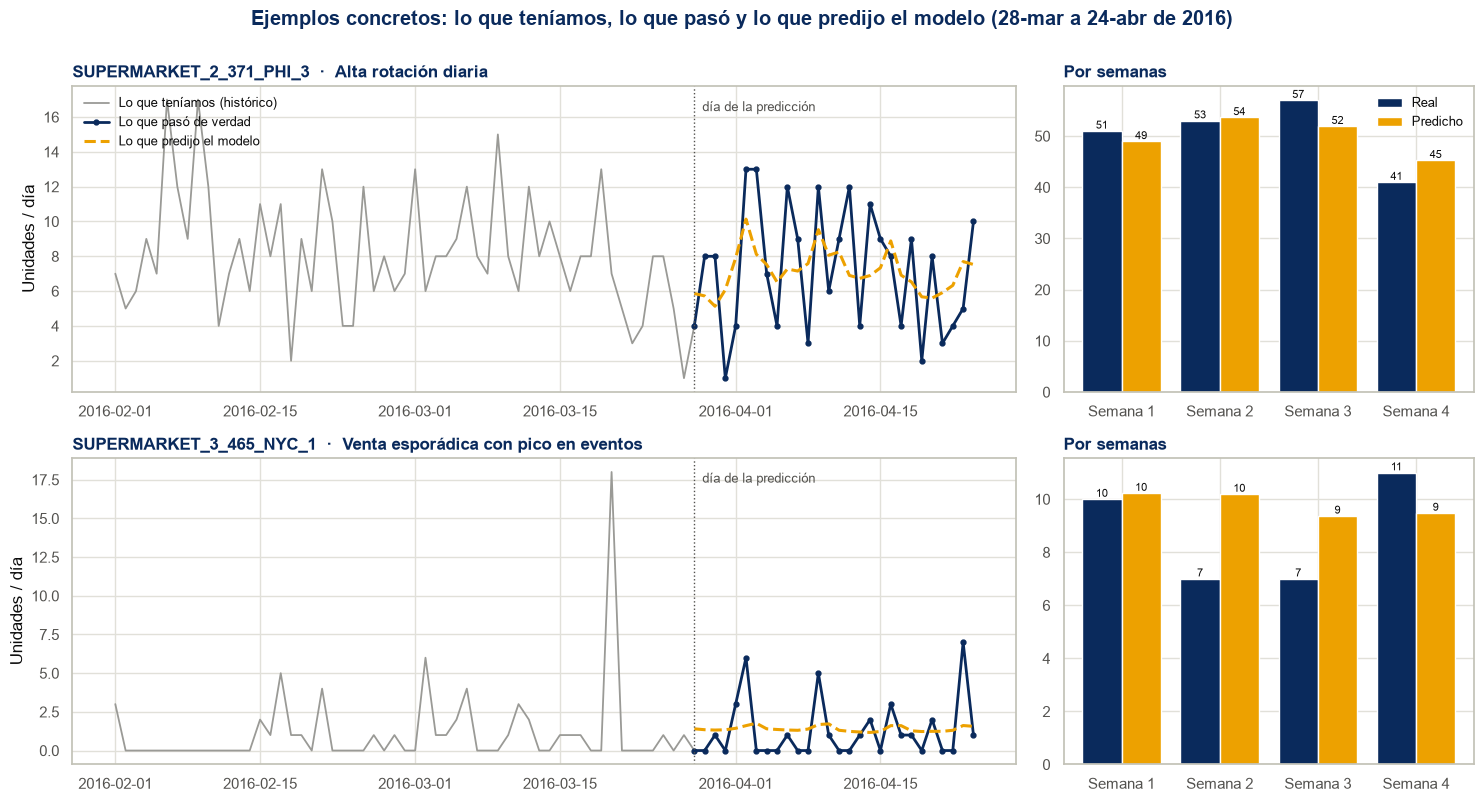

,grupo,días sin venta (%),error por día (WAPE %),error por semana (WAPE %),vendido en 4 semanas,predicho en 4 semanas
serie,,,,,,
SUPERMARKET_2_371_PHI_3,Alta rotación diaria,0.0,39.4,6.0,202.0,199.800003
SUPERMARKET_3_465_NYC_1,Venta esporádica con pico en eventos,50.0,113.0,20.9,35.0,39.299999


In [ ]:
import forecast_segmentacion as fs
import forecast_semanal as fw
# datos y predicciones del modelo de la sección 6 (LightGBM por bloques semanales), con los nombres usados en esta parte
V_, P_, cs_, cal_, meta_, folds_ = V, P, cumsum, cal, meta, FOLDS
preds_act = {('actual', f): predicciones[f]['LightGBM (bloques sem.)'] for f in range(len(FOLDS))}
EJEMPLOS = ['SUPERMARKET_2_371_PHI_3', 'SUPERMARKET_3_465_NYC_1']   # uno de venta diaria y uno de venta irregular
s_, e_ = folds_[2]                                                  # última ventana: 28-mar a 24-abr de 2016
fechas_ = pd.to_datetime(cal_['date'].values)
pred_ult = preds_act[('actual', 2)]
HIST = 56                                                           # 8 semanas de historia antes del corte

fig, axes = plt.subplots(2, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [2.3, 1]})
filas_ej = []
for fila, serie_id in enumerate(EJEMPLOS):
    i = int(np.nonzero(meta_['id'].values == serie_id)[0][0])
    grupo = meta_['nombre_grupo'].iloc[i]
    real = V_[i, s_:e_].astype(float); pred = pred_ult[i]
    ax = axes[fila, 0]
    ax.plot(fechas_[s_-HIST:s_+1], V_[i, s_-HIST:s_+1], color='#9a9a96', linewidth=1.3, label='Lo que teníamos (histórico)')
    ax.plot(fechas_[s_:e_], real, color=DSMARKET_NAVY, linewidth=2, marker='o', markersize=3.5, label='Lo que pasó de verdad')
    ax.plot(fechas_[s_:e_], pred, color=DSMARKET_GOLD, linewidth=2.2, linestyle='--', label='Lo que predijo el modelo')
    ax.axvline(fechas_[s_], color='#52514e', linestyle=':', linewidth=1)
    ax.text(fechas_[s_], ax.get_ylim()[1] * 0.95, '  día de la predicción', fontsize=9, color='#52514e', va='top')
    ax.set_title(f'{serie_id}  ·  {grupo}', color=DSMARKET_NAVY, fontweight='bold', loc='left')
    ax.set_ylabel('Unidades / día')
    if fila == 0: ax.legend(frameon=False, loc='upper left', fontsize=9)
    # la misma serie sumada por semanas
    rs, ps = fw.a_semanas(real[None])[0], fw.a_semanas(pred[None])[0]
    ax = axes[fila, 1]
    x = np.arange(4)
    ax.bar(x - 0.2, rs, width=0.4, color=DSMARKET_NAVY, label='Real')
    ax.bar(x + 0.2, ps, width=0.4, color=DSMARKET_GOLD, label='Predicho')
    for k in range(4):
        ax.text(x[k] - 0.2, rs[k], f'{rs[k]:.0f}', ha='center', va='bottom', fontsize=8)
        ax.text(x[k] + 0.2, ps[k], f'{ps[k]:.0f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([f'Semana {k+1}' for k in range(4)])
    ax.set_title('Por semanas', color=DSMARKET_NAVY, fontweight='bold', loc='left')
    if fila == 0: ax.legend(frameon=False, fontsize=9)
    filas_ej.append({'serie': serie_id, 'grupo': grupo,
                     'días sin venta (%)': (real == 0).mean() * 100,
                     'error por día (WAPE %)': fw.wape(real, pred),
                     'error por semana (WAPE %)': fw.wape(rs, ps),
                     'vendido en 4 semanas': real.sum(), 'predicho en 4 semanas': pred.sum()})
plt.suptitle('Ejemplos concretos: lo que teníamos, lo que pasó y lo que predijo el modelo (28-mar a 24-abr de 2016)',
             color=DSMARKET_NAVY, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()
pd.DataFrame(filas_ej).set_index('serie').round(1)

**Hallazgo: día a día el error parece enorme; por semanas, el modelo acierta bastante bien.**

- **Producto de venta diaria** (alimentación, Filadelfia): vende unas 8 unidades al día. Día a día el error es de un 39 % de las unidades, porque no es posible saber si mañana se venderán 4 o 12. **Por semanas baja a un 6 %**: se vendieron 51, 53, 57 y 41 unidades y el modelo predijo 49, 54, 52 y 45.
- **Producto de compra ocasional** (Nueva York): no se vende la mitad de los días. Día a día el error supera el 100 % (113 %), ya que no es posible adivinar qué día concreto aparecerá un comprador. **Por semanas baja a un 21 %**: se vendieron 35 unidades en las 4 semanas y el modelo predijo 39.

Para reponer una tienda no es necesario conocer el día exacto en que se venderá cada unidad, sino cuántas hacen falta en la semana. Por ello el error relevante es el semanal.

### 8.2. Métrica: WAPE semanal

Hasta ahora el error se medía **día a día** (RMSSE y WRMSSE, sección 3.1). Con tantos días sin ventas esto presenta dos problemas:

- En un producto que vende 0 o 1 unidades al día, el modelo predice, por ejemplo, 0,4. Cada día "falla" aunque en la semana acierte el total.
- La referencia del RMSSE (predecir cada día con el dato del día anterior) es difícil de explicar al negocio.

Se propone medir también el **WAPE semanal**: se suman las unidades predichas y vendidas de cada producto y tienda en cada semana y se calcula qué parte de lo vendido corresponde a error:

$$\text{WAPE} = \frac{\sum |\text{predicho} - \text{real}|}{\sum \text{real}} \times 100$$

Se lee directamente como *"el modelo se equivoca en un X % de las unidades de la semana"*. No falla con los ceros, porque divide entre el total vendido y no entre cada día, y encaja con la reposición, que también es semanal.

In [ ]:
# ¿Cuántos ceros hay si miramos días y si miramos semanas?
filas_m = []
for f, (s_, e_) in enumerate(folds_):
    y_ = V_[:, s_:e_].astype(np.float32)
    activa = ~np.isnan(P_[:, s_:e_])
    activa_sem = activa.reshape(len(y_), -1, 7).all(axis=2)
    base = fw.media_movil_28(V_, P_, s_, e_)
    pm = preds_act[('actual', f)]
    filas_m.append({'ventana': fw.NOMBRE_VENTANA[f'fold{f}'],
                    'días sin venta (%)': (y_[activa] == 0).mean() * 100,
                    'semanas sin venta (%)': (fw.a_semanas(y_)[activa_sem] == 0).mean() * 100,
                    'WAPE diario modelo': fw.wape(y_, pm), 'WAPE diario media móvil': fw.wape(y_, base),
                    'WAPE semanal modelo': fw.wape(fw.a_semanas(y_), fw.a_semanas(pm)),
                    'WAPE semanal media móvil': fw.wape(fw.a_semanas(y_), fw.a_semanas(base))})
tabla_m = pd.DataFrame(filas_m).set_index('ventana')
tabla_m.loc['media'] = tabla_m.mean()
tabla_m.round(1)

,días sin venta (%),semanas sin venta (%),WAPE diario modelo,WAPE diario media móvil,WAPE semanal modelo,WAPE semanal media móvil
ventana,,,,,,
Feb 2016,58.1,20.7,76.2,75.0,41.3,40.4
Mar 2016,57.4,19.2,76.0,75.9,41.0,39.9
Abr 2016,56.3,16.8,74.9,75.1,38.5,38.5
media,57.3,18.9,75.7,75.3,40.3,39.6


**Hallazgo: medido por semanas, el error se reduce a la mitad y los ceros casi desaparecen.**

| | Día a día | Por semanas |
|---|---|---|
| Huecos sin ventas | 57 % de los días | 19 % de las semanas |
| Error del modelo (WAPE) | 75,7 % | **40,3 %** |
| Error de la media móvil de 28 días (WAPE) | 75,3 % | 39,6 % |

*(media de las 3 ventanas de validación)*

- Más de la mitad de los días no registra ventas, de modo que medir día a día mezcla el error del modelo con el azar de qué día cae cada venta. Por semanas, los ceros bajan al 19 % y el error al 40 %.
- Con el WAPE semanal, el modelo y la media móvil de 28 días quedan **prácticamente empatados**. La ventaja del modelo en el WRMSSE (2,3 %, sección 6) procede de dos factores que el WAPE no premia: acierta mejor el reparto entre días de la semana (que desaparece al sumar la semana) y pesa más en los productos de mayor facturación.
- Para reponer todo el catálogo semana a semana, una media móvil bien construida da casi el mismo resultado que el modelo. El modelo aporta donde hay más dinero en juego y en los días con picos.

Se utilizan las dos métricas: el **WRMSSE** para comparar modelos, por ser la métrica de referencia en este tipo de problema, y el **WAPE semanal** para explicar el error al negocio y para la reposición.

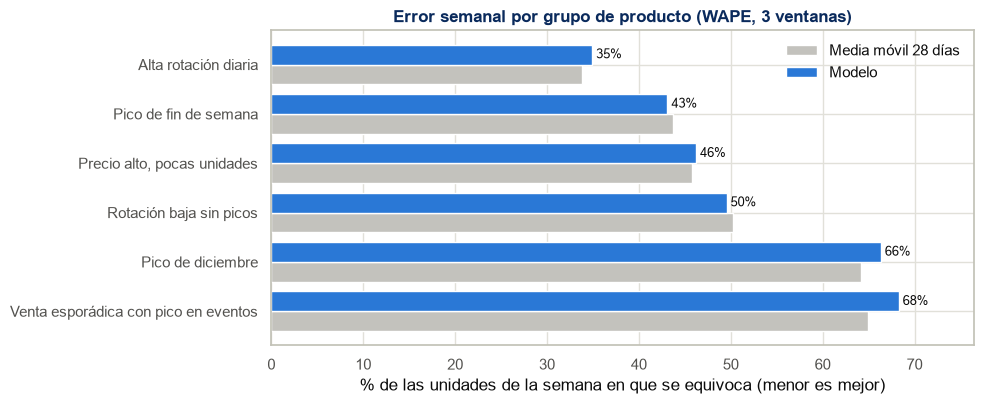

,WAPE semanal modelo,WAPE semanal media móvil,semanas sin venta (%),mejora sobre media móvil (puntos)
grupo,,,,
Alta rotación diaria,34.9,33.8,7.4,-1.1
Pico de fin de semana,43.1,43.7,13.5,0.6
"Precio alto, pocas unidades",46.2,45.8,24.5,-0.4
Rotación baja sin picos,49.5,50.2,20.8,0.7
Pico de diciembre,66.3,64.2,34.4,-2.2
Venta esporádica con pico en eventos,68.3,64.9,38.9,-3.3


In [ ]:
# Error semanal por grupo de producto (media de las 3 ventanas). Los grupos solo agrupan los resultados; no son variable del modelo
filas_gw = []
for f, (s_, e_) in enumerate(folds_):
    ys = fw.a_semanas(V_[:, s_:e_].astype(np.float32)); ps = fw.a_semanas(preds_act[('actual', f)])
    bs = fw.a_semanas(fw.media_movil_28(V_, P_, s_, e_))
    for g, idx in meta_.groupby('nombre_grupo').indices.items():
        filas_gw.append({'grupo': g, 'WAPE semanal modelo': fw.wape(ys[idx], ps[idx]),
                         'WAPE semanal media móvil': fw.wape(ys[idx], bs[idx]),
                         'semanas sin venta (%)': (ys[idx] == 0).mean() * 100})
tabla_gw = pd.DataFrame(filas_gw).groupby('grupo').mean().sort_values('WAPE semanal modelo')
tabla_gw['mejora sobre media móvil (puntos)'] = tabla_gw['WAPE semanal media móvil'] - tabla_gw['WAPE semanal modelo']

fig, ax = plt.subplots(figsize=(10, 4.2))
yy = np.arange(len(tabla_gw))
ax.barh(yy + 0.2, tabla_gw['WAPE semanal media móvil'], height=0.4, color='#c3c2bd', label='Media móvil 28 días')
ax.barh(yy - 0.2, tabla_gw['WAPE semanal modelo'], height=0.4, color=DSMARKET_BLUE, label='Modelo')
for k, v in enumerate(tabla_gw['WAPE semanal modelo']):
    ax.text(v, k - 0.2, f' {v:.0f}%', va='center', fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels(tabla_gw.index); ax.invert_yaxis()
ax.set_xlabel('% de las unidades de la semana en que se equivoca (menor es mejor)')
ax.set_title('Error semanal por grupo de producto (WAPE, 3 ventanas)', color=DSMARKET_NAVY, fontweight='bold')
ax.set_xlim(0, tabla_gw[['WAPE semanal modelo', 'WAPE semanal media móvil']].values.max() * 1.12)
ax.legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()
tabla_gw.round(1)

**Hallazgo: el error semanal depende sobre todo de la regularidad del producto.**

- **Alta rotación diaria** presenta el menor error (35 %), seguida de **Pico de fin de semana** (43 %). Son los dos grupos con menos semanas sin ventas (7 % y 14 %).
- **Precio alto, pocas unidades** y **Rotación baja sin picos** rondan el 46-50 %.
- **Venta esporádica con pico en eventos** (68 %) y **Pico de diciembre** (66 %) son los peores: más de un tercio de sus semanas no registra ventas, y en Navidad estas ventanas quedan fuera de su temporada.
- Por semanas, el modelo y la media móvil quedan muy cerca en todos los grupos: el modelo gana por poco en Pico de fin de semana y en Rotación baja sin picos (0,5-0,6 puntos), y la media móvil en los demás.

El modelo funciona mejor donde está el volumen.

## 9. Temporada alta: eventos semanales y más historia

Las tres ventanas de validación corresponden a febrero-abril, pero el negocio concentra su actividad en noviembre y diciembre. Se evaluaron dos ventanas adicionales de 2015, entrenando únicamente con datos anteriores: **6 de noviembre a 3 de diciembre** (arranque de temporada, con Thanksgiving) y **4 a 31 de diciembre** (pico, cierre de Navidad y fin de año). Resultado del modelo de 180 días:

| Ventana | LightGBM | Media móvil | Ventaja del modelo |
|---|---|---|---|
| Feb-Abr 2016 (3 ventanas originales) | 1.0407 | 1.0657 | 2,4 % |
| Nov 2015 (arranque de temporada) | 1.0520 | 1.0850 | 3,0 % |
| **Dic 2015 (pico, Navidad y fin de año)** | **1.1119** | **1.1161** | **0,4 %** |

En noviembre el modelo se sostiene, pero **en diciembre el error sube un 7 % y la ventaja sobre la media móvil casi desaparece**. Por días se identifican tres causas:

1. **El 25 de diciembre el modelo predijo 36.118 unidades y las ventas reales fueron 14.** La tienda cierra y el modelo no puede saberlo.
2. **Subestimación de la subida previa a Navidad:** los días 22, 23 y 24 con errores de −17 %, −23 % y −22 %.
3. **Subestimación del 31 de diciembre** en un 29 %, el pico de fin de año.

La causa del error de Navidad no es el algoritmo: la ventana de entrenamiento de ese fold (7 de junio a 3 de diciembre de 2015) **no contiene ninguna Navidad**. El modelo nunca observó una. Se evalúan dos remedios: variables de evento a nivel semanal (9.1) y una ventana de entrenamiento más larga (9.2).

### 9.1. Eventos a nivel semanal

Hasta ahora el modelo solo conocía si **ese día** había un evento. Sin embargo, las compras de Navidad, Thanksgiving o la Super Bowl se reparten por los días anteriores. Se añaden cuatro variables que consideran la semana:

| Variable | Descripción |
|---|---|
| `sem_evento` | si en esa semana (sábado a viernes, como el calendario original) hay algún evento |
| `evento_semana` | qué evento hay esa semana |
| `dias_hasta_evento` | días que faltan para el próximo evento (hasta 15) |
| `dias_desde_evento` | días transcurridos desde el último (hasta 8) |

Todas se conocen de antemano por el calendario, por lo que no utilizan información del futuro. Se reentrena el modelo con ellas y se compara con el de la sección 6 en las 3 ventanas de validación y en las 2 de temporada alta.


In [ ]:
# Comparación: modelo de la sección 6 frente al mismo modelo con las 4 variables de evento semanal
V16 = fw.ventanas(cal_, folds_)
filas_ev, imp_ev = [], []
for nombre, (s_, e_) in V16.items():
    y_ = V_[:, s_:e_].astype(np.float32); h_ = V_[:, :s_].astype(np.float32)
    for config in fw.CONFIGS:
        r = fw.entrenar(config, nombre, (s_, e_), V_, P_, cs_, cal_, meta_, None)
        filas_ev.append({'ventana': fw.NOMBRE_VENTANA[nombre], 'modelo': config,
                         'WRMSSE': fs.wrmsse(y_, r['pred'], h_, P_[:, :s_]),
                         'WAPE semanal': fw.wape(fw.a_semanas(y_), fw.a_semanas(r['pred']))})
        if config == 'eventos_semanales':
            imp_ev.append(r['importancia'] / r['importancia'].sum() * 100)
ev = pd.DataFrame(filas_ev)
tabla_ev = ev.pivot(index='ventana', columns='modelo', values=['WRMSSE', 'WAPE semanal'])
tabla_ev = tabla_ev.reindex([fw.NOMBRE_VENTANA[k] for k in V16])
tabla_ev.round(4)

WRMSSE                                \
modelo                   actual actual_400d eventos_semanales   
ventana                                                         
Feb 2016                 1.0776      1.0752            1.0754   
Mar 2016                 1.0415      1.0404            1.0402   
Abr 2016                 1.0029      0.9989            1.0022   
Nov 2015 (Thanksgiving)  1.0520      1.0177            1.0548   
Dic 2015 (Navidad)       1.1119      1.0497            1.1116   

                                               WAPE semanal              \
modelo                  eventos_semanales_400d       actual actual_400d   
ventana                                                                   
Feb 2016                                1.0756      41.2871     40.5838   
Mar 2016                                1.0383      40.9864     40.1285   
Abr 2016                                0.9994      38.5130     37.8041   
Nov 2015 (Thanksgiving)                 1.0177      45.1773     40.5057   
Dic 2015 (Navidad)                      1.0484      47.3711     41.5905   

                                                                  
modelo                  eventos_semanales eventos_semanales_400d  
ventana                                                           
Feb 2016                          41.1956                40.7330  
Mar 2016                          40.9548                40.0666  
Abr 2016                          38.2361                37.8292  
Nov 2015 (Thanksgiving)           45.5765                40.3454  
Dic 2015 (Navidad)                47.5438                41.5228

In [ ]:
# ¿Cuánto pesan las variables nuevas dentro del modelo? (% de la importancia, media de las 5 ventanas)
imp_ev_m = pd.concat(imp_ev, axis=1).mean(axis=1)
pd.DataFrame({'% de la importancia': imp_ev_m[fw.EXTRA_SEMANAL + ['event']].round(2)})

,% de la importancia
sem_evento,0.00
evento_semana,0.05
dias_hasta_evento,0.07
dias_desde_evento,0.05
event,0.33


**Hallazgo: con 180 días de historia, los eventos semanales apenas modifican el modelo.** Las diferencias son de una o dos milésimas en ambos sentidos.

| Ventana | Modelo de la sección 6 | Con eventos semanales |
|---|---|---|
| Feb 2016 | 1,0776 | 1,0754 |
| Mar 2016 | 1,0415 | 1,0402 |
| Abr 2016 | 1,0029 | 1,0022 |
| Nov 2015 (Thanksgiving) | 1,0520 | 1,0548 |
| Dic 2015 (Navidad) | 1,1119 | 1,1116 |

*(WRMSSE, menor es mejor; el WAPE semanal tampoco varía más de 0,4 puntos)*

Las cuatro variables nuevas juntas pesan un **0,17 %** de la importancia del modelo, frente a más de la mitad de la media móvil de 28 días. Las razones son:

1. **El modelo aprende de los últimos 180 días.** Para predecir diciembre aprende de junio a noviembre y no ha visto ninguna Navidad, por lo que no puede saber qué ocurre la semana previa.
2. **El calendario tiene pocos eventos:** 5 tipos (Super Bowl, Ramadán, Thanksgiving, Año Nuevo y Semana Santa), más Navidad y Labor Day añadidos por fecha. En cada ventana de entrenamiento entran 2 o 3, cada uno con su propio efecto.
3. **El modelo ya observa el año anterior** mediante `lag_364`, que recoge buena parte del efecto de cada temporada.

Para que las variables funcionen, el modelo necesita **más de un año de historia**. Se prueba en 9.2.

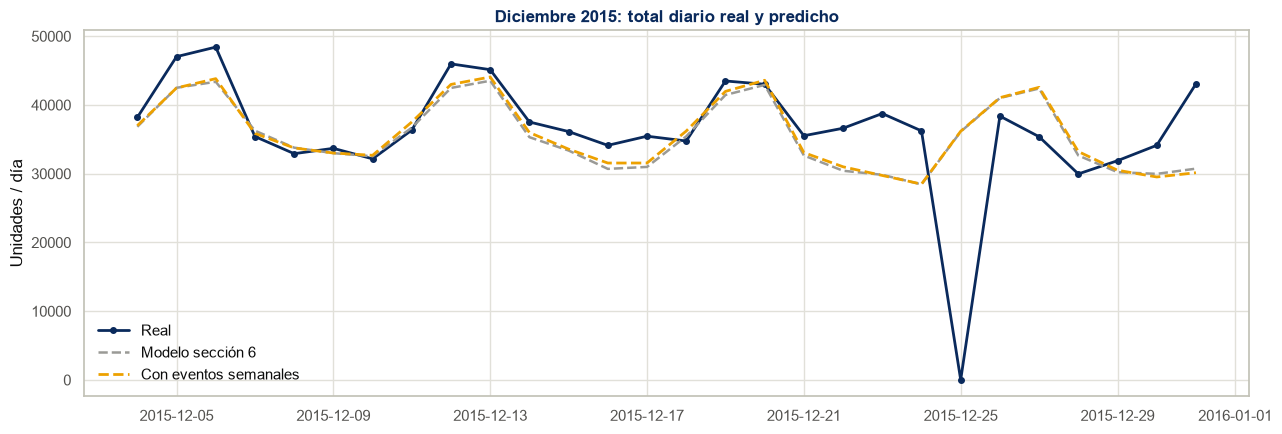

,real,modelo sección 6,con eventos semanales,error modelo sección 6 (%),error con eventos semanales (%)
semana,,,,,
2015-12-04 a 2015-12-10,267797,258262.796875,258583.593750,-3.6,-3.4
2015-12-11 a 2015-12-17,270680,253053.593750,257228.296875,-6.5,-5.0
2015-12-18 a 2015-12-24,268368,241154.500000,244068.093750,-10.1,-9.1
2015-12-25 a 2015-12-31,212812,243100.796875,243188.500000,14.2,14.3


In [ ]:
# Diciembre día a día: total de la cadena, con y sin eventos semanales
s_, e_ = V16['dic2015']
f_dic = pd.to_datetime(cal_['date'].values[s_:e_])
real_d = V_[:, s_:e_].sum(axis=0)
pa = fw.entrenar('actual', 'dic2015', (s_, e_), V_, P_, cs_, cal_, meta_, None)['pred'].sum(axis=0)
pe = fw.entrenar('eventos_semanales', 'dic2015', (s_, e_), V_, P_, cs_, cal_, meta_, None)['pred'].sum(axis=0)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(f_dic, real_d, color=DSMARKET_NAVY, linewidth=2, marker='o', markersize=4, label='Real')
ax.plot(f_dic, pa, color='#9a9a96', linewidth=1.8, linestyle='--', label='Modelo sección 6')
ax.plot(f_dic, pe, color=DSMARKET_GOLD, linewidth=2, linestyle='--', label='Con eventos semanales')
ax.set_title('Diciembre 2015: total diario real y predicho', color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
sem_dic = pd.DataFrame({'semana': [f'{f_dic[7*k].date()} a {f_dic[7*k+6].date()}' for k in range(4)],
                        'real': fw.a_semanas(real_d[None])[0], 'modelo sección 6': fw.a_semanas(pa[None])[0],
                        'con eventos semanales': fw.a_semanas(pe[None])[0]}).set_index('semana')
for c in ['modelo sección 6', 'con eventos semanales']:
    sem_dic[f'error {c} (%)'] = (sem_dic[c] - sem_dic['real']) / sem_dic['real'] * 100
sem_dic.round(1)

**Hallazgo: por semanas se identifica dónde falla diciembre, y las variables semanales no lo corrigen.**

- En las tres primeras semanas el modelo **se queda corto**, cada vez más al acercarse Navidad: un 4 %, un 7 % y un 10 % por debajo de lo vendido.
- La semana del 25 al 31 **se pasa en un 14 %**, porque predice unas 36.000 unidades el día 25, cuando la tienda cierra.
- Las dos versiones del modelo hacen prácticamente lo mismo (la de eventos semanales mejora uno o dos puntos las semanas 2 y 3).

### 9.2. Más historia: 400 días en lugar de 180

Se repite la comparación entrenando con los **400 días** anteriores a cada ventana. Así, para predecir diciembre de 2015 el modelo ya ha observado la Navidad, el Thanksgiving y el Año Nuevo de 2014. Se evalúan las dos versiones, sin y con eventos semanales, para separar el efecto de la historia del efecto de las variables nuevas.

In [ ]:
# Las 4 versiones en las 5 ventanas
ORDEN_CFG = ['actual', 'eventos_semanales', 'actual_400d', 'eventos_semanales_400d']
NOMBRE_CFG = {'actual': '180 días', 'eventos_semanales': '180 días + eventos sem.',
              'actual_400d': '400 días', 'eventos_semanales_400d': '400 días + eventos sem.'}
filas_l = []
for nombre, (s_, e_) in V16.items():
    y_ = V_[:, s_:e_].astype(np.float32); h_ = V_[:, :s_].astype(np.float32)
    for config in ORDEN_CFG:
        r = fw.entrenar(config, nombre, (s_, e_), V_, P_, cs_, cal_, meta_, None)
        filas_l.append({'ventana': fw.NOMBRE_VENTANA[nombre], 'versión': NOMBRE_CFG[config],
                        'WRMSSE': fs.wrmsse(y_, r['pred'], h_, P_[:, :s_]),
                        'WAPE semanal': fw.wape(fw.a_semanas(y_), fw.a_semanas(r['pred']))})
larg = pd.DataFrame(filas_l)
cols = [NOMBRE_CFG[c] for c in ORDEN_CFG]
filas_idx = [fw.NOMBRE_VENTANA[k] for k in V16]
t_w = larg.pivot(index='ventana', columns='versión', values='WRMSSE').reindex(filas_idx)[cols]
t_w.loc['media feb-abr'] = t_w.iloc[:3].mean()
t_a = larg.pivot(index='ventana', columns='versión', values='WAPE semanal').reindex(filas_idx)[cols]
t_a.loc['media feb-abr'] = t_a.iloc[:3].mean()
print('WRMSSE (menor es mejor)'); display(t_w.round(4))
print('WAPE semanal, % (menor es mejor)'); display(t_a.round(1))

WRMSSE (menor es mejor)


versión,180 días,180 días + eventos sem.,400 días,400 días + eventos sem.
ventana,,,,
Feb 2016,1.0776,1.0754,1.0752,1.0756
Mar 2016,1.0415,1.0402,1.0404,1.0383
Abr 2016,1.0029,1.0022,0.9989,0.9994
Nov 2015 (Thanksgiving),1.0520,1.0548,1.0177,1.0177
Dic 2015 (Navidad),1.1119,1.1116,1.0497,1.0484
media feb-abr,1.0407,1.0393,1.0382,1.0378


WAPE semanal, % (menor es mejor)


versión,180 días,180 días + eventos sem.,400 días,400 días + eventos sem.
ventana,,,,
Feb 2016,41.3,41.2,40.6,40.7
Mar 2016,41.0,41.0,40.1,40.1
Abr 2016,38.5,38.2,37.8,37.8
Nov 2015 (Thanksgiving),45.2,45.6,40.5,40.3
Dic 2015 (Navidad),47.4,47.5,41.6,41.5
media feb-abr,40.3,40.1,39.5,39.5


**Hallazgo: con más historia el modelo mejora mucho en temporada alta y no empeora el resto del año.**

| Ventana | 180 días | 400 días | 400 días + eventos semanales |
|---|---|---|---|
| Nov 2015 (Thanksgiving) | 1,0520 | **1,0177** | **1,0177** |
| Dic 2015 (Navidad) | 1,1119 | 1,0497 | **1,0484** |
| Media feb-abr 2016 | 1,0407 | 1,0382 | **1,0378** |

*(WRMSSE, menor es mejor)*

- **Diciembre mejora un 5,7 % y noviembre un 3,3 %**, la mayor mejora de todo el proyecto, precisamente en los meses de mayor actividad.
- **Prácticamente toda la mejora procede de la historia adicional** (400 días). Las variables de evento semanal añaden un 0,1 % en diciembre y nada en noviembre ni el resto del año.
- **En febrero-abril también mejora ligeramente** (de 1,0407 a 1,0378), por lo que alargar la historia no tiene coste en precisión; solo en tiempo de cálculo, ya que cada entrenamiento tarda algo más del doble.
- Con el **WAPE semanal** ocurre lo mismo: diciembre baja del 47,4 % al 41,5 % y, en febrero-abril, el modelo pasa del 40,3 % al 39,5 %, a la altura de la media móvil de 28 días (39,6 %).

Los eventos deben considerarse con perspectiva semanal y anual, pero lo que más pesa no son las variables nuevas, sino que el modelo pueda **observar el evento del año anterior**.

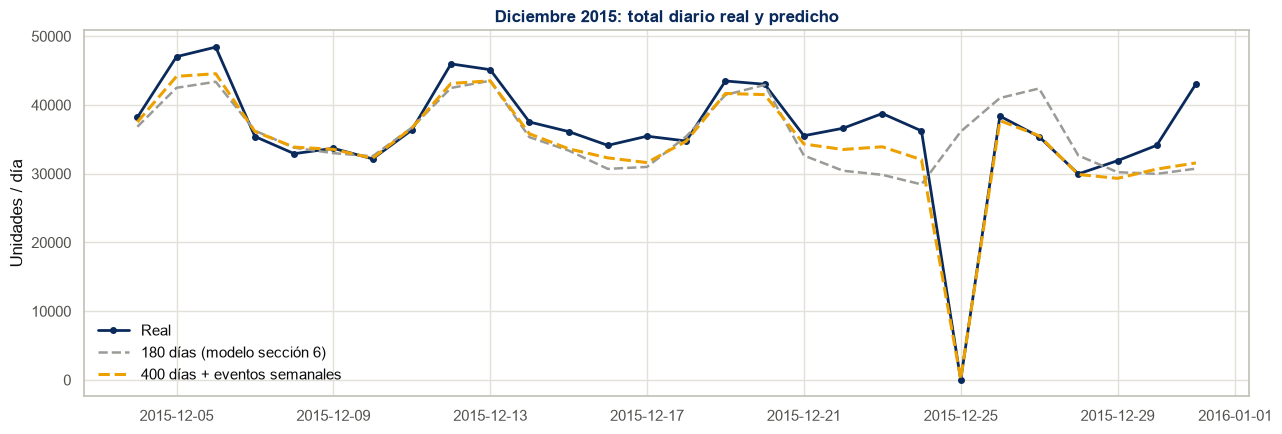

,real,modelo sección 6,400 días + eventos semanales,error modelo sección 6 (%),error 400 días + eventos (%)
semana,,,,,
2015-12-04 a 2015-12-10,267797,258262.796875,262004.000000,-3.6,-2.2
2015-12-11 a 2015-12-17,270680,253053.593750,256621.796875,-6.5,-5.2
2015-12-18 a 2015-12-24,268368,241154.500000,251700.203125,-10.1,-6.2
2015-12-25 a 2015-12-31,212812,243100.796875,194803.906250,14.2,-8.5


In [ ]:
# Diciembre con 400 días de historia
s_, e_ = V16['dic2015']
p400 = fw.entrenar('eventos_semanales_400d', 'dic2015', (s_, e_), V_, P_, cs_, cal_, meta_, None)['pred'].sum(axis=0)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(f_dic, real_d, color=DSMARKET_NAVY, linewidth=2, marker='o', markersize=4, label='Real')
ax.plot(f_dic, pa, color='#9a9a96', linewidth=1.8, linestyle='--', label='180 días (modelo sección 6)')
ax.plot(f_dic, p400, color=DSMARKET_GOLD, linewidth=2.2, linestyle='--', label='400 días + eventos semanales')
ax.set_title('Diciembre 2015: total diario real y predicho', color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día'); ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.show()
sem_dic['400 días + eventos semanales'] = fw.a_semanas(p400[None])[0]
sem_dic['error 400 días + eventos (%)'] = (sem_dic['400 días + eventos semanales'] - sem_dic['real']) / sem_dic['real'] * 100
sem_dic[['real', 'modelo sección 6', '400 días + eventos semanales',
         'error modelo sección 6 (%)', 'error 400 días + eventos (%)']].round(1)

**Hallazgo: con 400 días de historia el modelo aprende por sí solo los problemas de diciembre, salvo el pico de fin de año.**

1. **Cierre del 25 de diciembre.** Antes se predecían unas 36.000 unidades ese día; ahora se predicen **123** (las ventas reales fueron 14). Lo aprende al observar la Navidad de 2014, sin reglas manuales.
2. **Subida previa a Navidad.** La semana del 18 al 24 pasa de un error del −10,1 % a **−6,2 %**, y los días 22, 23 y 24 pasan de −17 %, −23 % y −22 % a −8 %, −13 % y −12 %.
3. **Semana del 25 al 31.** Pasa de un error de +14,2 % a −8,5 %. El pico del 31 de diciembre sigue sin captarse (−27 %).

En noviembre, la semana de Black Friday (27 de noviembre a 3 de diciembre) pasa de un error de +10,3 % a **+0,2 %**.

## 10. Sesgo e intervalos de predicción

### 10.1. El sesgo del −2 %

El modelo subestima de forma sistemática. La corrección obvia es multiplicar por un factor estimado en validación. Se prueba de dos formas: con el promedio de los folds 1 y 2, y solo con el fold más reciente. La diferencia entre ambas informa sobre la naturaleza del sesgo.

In [ ]:
# Factor de calibración de cada ventana: unidades reales / unidades predichas por el modelo de bloques semanales
factores = []
for f, (s_f, e_f) in enumerate(FOLDS):
    factores.append(float(V[:, s_f:e_f].sum() / predicciones[f]['LightGBM (bloques sem.)'].sum()))
cal_factores = {'factores': factores}
pickle.dump(cal_factores, open(f"{CACHE}/calibracion.pkl", "wb"))
for i, f in enumerate(cal_factores['factores']):
    print(f"  fold {i+1}: factor real/predicho = {f:.4f}")

s3, e3 = FOLDS[2]
pred3 = predicciones[2]['LightGBM (bloques sem.)']
y3 = V[:, s3:e3].astype(np.float32); h3 = V[:, :s3].astype(np.float32); Ph3 = P[:, :s3]
filas_cal = []
for nombre, factor in [('Sin calibrar', 1.0),
                       ('Factor promedio folds 1-2', float(np.mean(cal_factores['factores'][:2]))),
                       ('Factor del fold más reciente', cal_factores['factores'][1])]:
    yp = pred3 * factor
    filas_cal.append({'variante': nombre, 'factor': round(factor, 4),
                      'WRMSSE': wrmsse(y3, yp, h3, Ph3), 'MAE': mae(y3, yp),
                      'sesgo_%': (yp.sum() - y3.sum()) / y3.sum() * 100})
pd.DataFrame(filas_cal).set_index('variante').round(4)


  fold 1: factor real/predicho = 1.0733
  fold 2: factor real/predicho = 1.0255
  fold 3: factor real/predicho = 1.0198


,factor,WRMSSE,MAE,sesgo_%
variante,,,,
Sin calibrar,1.0000,1.0029,1.0378,-1.9384
Factor promedio folds 1-2,1.0494,1.0049,1.0494,2.9056
Factor del fold más reciente,1.0255,1.0034,1.0434,0.5616


**Hallazgo: el sesgo puede corregirse, pero no es estable, y corregirlo no mejora la precisión.**

Los factores necesarios en cada fold son 1.0733, 1.0255 y 1.0198. El primero requiere una corrección del 7,3 % y los otros dos del 2-3 %: **el sesgo no es una constante del modelo, cambia con el período**. Por tanto:

- Calibrar con el **promedio de los folds 1-2** (factor 1.0494) sobrecorrige: el sesgo del fold 3 pasa de −1,94 % a **+2,91 %**, y tanto el WRMSSE como el MAE **empeoran**.
- Calibrar con el **fold más reciente** (factor 1.0255) deja el sesgo en **+0,56 %**, prácticamente cero, con el WRMSSE prácticamente intacto (1.0029 → 1.0034).

Multiplicar todas las predicciones por una constante no las vuelve más certeras, solo redistribuye el error. Se justifica porque para reponer stock **el signo del error importa más que su tamaño**: un modelo que se queda corto un 2 % de forma sistemática genera roturas sistemáticas, mes tras mes, en los mismos productos.

**Recomendación:** aplicar el factor recalculado con la ventana de validación más reciente en cada reentrenamiento, nunca un factor fijo estimado una sola vez.

### 10.2. De un número a un rango

Hasta aquí se entrega un valor por producto y día. Para reponer stock no basta: si se almacena según la predicción media, se queda corto **la mitad de las veces por definición**, y en la práctica más, porque la demanda de estos productos es asimétrica.

Se entrena un segundo modelo con **objetivo cuantílico al 90 %**. El **percentil 90 (p90)** de un producto en un día es el **techo de demanda esperado**: el nivel de ventas que solo se supera 1 de cada 10 días. No es el máximo absoluto (algún día puntual puede superarlo) ni una previsión de ventas, que es lo que estima la predicción media, sino un escenario de demanda alta. Por eso es el insumo de una política de stock con nivel de servicio del 90 %: almacenar hasta el p90 cubre la demanda en 9 de cada 10 días.

Se valida con la **cobertura empírica** (¿la demanda real queda por debajo del p90 en el 90 % de los casos?) y con la **pinball loss**, métrica propia de la regresión cuantílica.

In [ ]:
q90 = np.load(f"{CACHE}/p90_eval.npy")
media3 = predicciones[2]['LightGBM (bloques sem.)']
valido = ~np.isnan(P[:, s3:e3])          # solo celdas donde el producto estaba efectivamente a la venta

def pinball(y, q, alpha):
    d = y - q
    return float(np.mean(np.maximum(alpha * d, (alpha - 1) * d)))

mm3 = np.repeat(V[:, s3-28:s3].astype(np.float32).mean(axis=1, keepdims=True), e3 - s3, axis=1)
print(f"Cobertura empírica del p90:              {(y3[valido] <= q90[valido]).mean():.1%}   (objetivo: 90%)")
print(f"Cobertura de la predicción media:        {(y3[valido] <= media3[valido]).mean():.1%}")
print()
print(f"Pinball loss (α=0.9) del modelo p90:     {pinball(y3[valido], q90[valido], 0.9):.4f}")
print(f"Pinball loss usando la predicción media: {pinball(y3[valido], media3[valido], 0.9):.4f}")
print(f"Pinball loss del atajo 'media móvil × 2.5': {pinball(y3[valido], (mm3 * 2.5)[valido], 0.9):.4f}")
print()
print(f"Unidades a stockear según la media: {media3[valido].sum():>12,.0f}")
print(f"Unidades a stockear según el p90:   {q90[valido].sum():>12,.0f}  (+{(q90[valido].sum()/media3[valido].sum()-1)*100:.0f}%)")
print(f"Demanda real del período:           {y3[valido].sum():>12,.0f}")

Cobertura empírica del p90:              90.0%   (objetivo: 90%)
Cobertura de la predicción media:        67.9%

Pinball loss (α=0.9) del modelo p90:     0.3101
Pinball loss usando la predicción media: 0.5297
Pinball loss del atajo 'media móvil × 2.5': 0.3667

Unidades a stockear según la media:    1,160,683
Unidades a stockear según el p90:      2,629,378  (+127%)
Demanda real del período:              1,183,626


**Hallazgo: el modelo cuantílico está bien calibrado y revela el coste real del nivel de servicio.**

La cobertura empírica del p90 es del **90,0 %** frente a un objetivo del 90 %: la demanda real queda por debajo del techo estimado en 9 de cada 10 días-producto.

En pinball loss el modelo obtiene **0,3101**, frente a 0,5297 si se utilizara la predicción media como p90 y 0,3667 con el atajo "media móvil × 2,5". El modelo cuantílico supera tanto a la media como a la heurística que aplicaría un equipo de operaciones.

- La predicción media cubre la demanda real solo el **67,9 %** de las veces: **si se almacena según la media, hay faltante en 1 de cada 3 combinaciones producto-día.**
- Alcanzar un nivel de servicio del 90 % requiere **+127 % de stock** (2.629.378 unidades frente a 1.160.682 para las mismas cuatro semanas).

Ese salto no es un defecto del modelo, sino la naturaleza del problema: cubrir la cola de una demanda muy asimétrica es caro. Pero ahora es una **decisión explícita y cuantificada**. Con los dos modelos se construye la curva de servicio frente a capital inmovilizado, que la Tarea 4 utiliza para decidir el nivel de servicio por grupo.

## 11. Precios de las semanas futuras

En la sección 2 se dejaron fuera las filas de `item_prices.csv` sin `yearweek`: son los precios de las semanas posteriores al último dato de ventas. El modelo utiliza el precio de cada día como variable, y el precio de los 28 días a predecir no se conoce, salvo que se utilicen esas filas. Se comparan dos opciones:

- **Precio arrastrado:** el último precio observado de cada serie se mantiene durante todo el horizonte (supuesto original).
- **Precio real:** se utiliza el precio de la semana correspondiente a cada día, tomado de las filas sin `yearweek`.

Se mide en dos escenarios con **el mismo modelo entrenado**, predicho con cada una de las dos matrices de precios (`experimentos_t3.py` y `exp_precios_paso.py`):

1. **Simulación** en la última ventana de validación (28 de marzo a 24 de abril de 2016), donde sí se conocen las ventas reales: el precio arrastrado es el último anterior a la ventana.
2. **Entrega** (25 de abril a 22 de mayo de 2016): se comparan las predicciones y no puede medirse el error.

In [ ]:
# Precio arrastrado frente a precio real de las semanas futuras
import forecast_semanal as fw
D3 = f"{CACHE}/exp3"
s_, e_ = folds_[2]
y_ = V_[:, s_:e_].astype(np.float32); h_ = V_[:, :s_].astype(np.float32)

# 1) Simulación en la última ventana de validación (mismo modelo, dos matrices de precios)
P_arr = P_.copy()
P_arr[:, s_:e_] = np.where(np.isnan(P_[:, s_:e_]), np.nan, P_[:, s_ - 1:s_])        # último precio anterior a la ventana
cambian_sim = int((np.nan_to_num(P_[:, s_:e_]) != np.nan_to_num(P_arr[:, s_:e_])).any(axis=1).sum())
sim = {'Precio arrastrado': np.load(f"{D3}/sim_media_arrastrado.npy"), 'Precio real': np.load(f"{D3}/sim_media_real.npy")}
tab_sim = pd.DataFrame({k: {'WRMSSE': fs.wrmsse(y_, v, h_, P_[:, :s_]),
                            'WAPE semanal (%)': fw.wape(fw.a_semanas(y_), fw.a_semanas(v)),
                            'Unidades previstas': v.sum()} for k, v in sim.items()}).T
print(f"Simulación (28-mar a 24-abr de 2016): series cuyo precio cambia respecto al arrastrado: {cambian_sim:,} de {len(V_):,}")
display(tab_sim.round(4))

# 2) Entrega: 28 días siguientes al último dato
PF = fs.cargar_precios_futuros(meta_)
cambian_ent = int((np.nan_to_num(PF) != np.nan_to_num(P_[:, -1:])).any(axis=1).sum())
ent_m = {'Precio arrastrado': np.load(f"{D3}/ent_media_arrastrado.npy"), 'Precio real': np.load(f"{D3}/ent_media_real.npy")}
ent_p = {'Precio arrastrado': np.maximum(np.load(f"{D3}/ent_p90_arrastrado.npy"), ent_m['Precio arrastrado']),
         'Precio real': np.maximum(np.load(f"{D3}/ent_p90_real.npy"), ent_m['Precio real'])}
tab_ent = pd.DataFrame({k: {'Predicción media (unidades)': ent_m[k].sum(), 'Percentil 90 (unidades)': ent_p[k].sum()} for k in ent_m}).T
tab_ent.loc['Diferencia (%)'] = (tab_ent.loc['Precio real'] / tab_ent.loc['Precio arrastrado'] - 1) * 100
print(f"Entrega (25-abr a 22-may de 2016): series cuyo precio cambia en las 4 semanas futuras: {cambian_ent:,} de {len(V_):,}")
display(tab_ent.round(2))
sem_rel = fw.a_semanas(ent_m['Precio real']).sum(axis=0) / fw.a_semanas(ent_m['Precio arrastrado']).sum(axis=0)
print('Cociente precio real / arrastrado por semana (media):', ' · '.join(f'S{k+1} {v:.4f}' for k, v in enumerate(sem_rel)))


Simulación (28-mar a 24-abr de 2016): series cuyo precio cambia respecto al arrastrado: 570 de 30,490


,WRMSSE,WAPE semanal (%),Unidades previstas
Precio arrastrado,1.0000,37.9270,1157086.00
Precio real,0.9994,37.8292,1156644.75


Entrega (25-abr a 22-may de 2016): series cuyo precio cambia en las 4 semanas futuras: 793 de 30,490


,Predicción media (unidades),Percentil 90 (unidades)
Precio arrastrado,1171535.75,2642811.50
Precio real,1171954.75,2645067.75
Diferencia (%),0.04,0.09


Cociente precio real / arrastrado por semana (media): S1 1.0001 · S2 1.0003 · S3 1.0005 · S4 1.0005


**Hallazgo: el efecto de utilizar los precios reales es mínimo, porque casi ningún precio cambia en el horizonte.**

- Solo **793 de las 30.490 series** (un 2,6 %) cambian de precio en las 4 semanas futuras. En el resto el precio real coincide con el arrastrado, por lo que ambas opciones dan la misma predicción. En la ventana de simulación son 570 series.
- En la simulación, el precio real mejora el WRMSSE de 1.0000 a **0.9994** y el WAPE semanal de 37,93 % a 37,83 %. La diferencia es compatible con el ruido de validación.
- En la entrega, la predicción media sube un **0,04 %** (1.171.955 frente a 1.171.536 unidades), con un efecto algo mayor en las últimas semanas, y el p90 un 0,09 %.

**Decisión.** Utilizar los precios reales es correcto en principio, ya que se trata de información conocida, pero no modifica ninguna conclusión. Los ficheros de entrega del repositorio mantienen el precio arrastrado (sección 12) para no alterar las cifras del resto del proyecto (notebook 04, lakehouse y panel). Ambas versiones se conservan en `cache_forecast_sin_clusters/`: `final_futuro_*` (arrastrado) y `final_futuro_*_pf` (precios reales). Adoptar la segunda requiere ejecutar `python3 modelo_final.py --precios-futuros` y regenerar `carga_predicciones.py`.

*Nota:* la predicción de entrega guardada y la del experimento se entrenaron en momentos distintos, por lo que difieren un 0,2 % por el propio entrenamiento. La comparación válida es la pareja del experimento (mismo modelo, distinto precio).

## 12. Modelo final y entrega

Con lo visto en la sección 9, el modelo final se entrena con **400 días de historia**, las **variables de evento semanal**, sin la variable de grupo de producto (el experimento `03b` mostró que no aporta). El resto coincide con la sección 6: LightGBM por bloques semanales, objetivo Tweedie para la predicción media y un segundo modelo con objetivo cuantílico para el percentil 90, que es el utilizado en la reposición (notebook 04). Como en la sección 10, el percentil 90 se fuerza a no quedar nunca por debajo de la media.

El código está en `modelo_final.py`. En primer lugar se evalúa en la última ventana de validación (28 de marzo a 24 de abril de 2016), la misma que simula el notebook 04. Después se reentrena con todos los datos y se predicen los 28 días siguientes, que constituyen los ficheros de entrega.

In [ ]:
# Modelo final: 400 días de historia + eventos semanales, sin grupo de producto (modelo_final.py)
import modelo_final as mf
s_, e_ = folds_[2]
y_ = V_[:, s_:e_].astype(np.float32); h_ = V_[:, :s_].astype(np.float32)
fm = np.load(f'{CACHE}/final_eval_media.npy'); fp = np.load(f'{CACHE}/final_eval_p90.npy')
valido = ~np.isnan(P_[:, s_:e_])
def pinball(y, q, a=0.9):
    d = y - q
    return float(np.mean(np.maximum(a * d, (a - 1) * d)))
comp_final = pd.DataFrame({
    'modelo de la sección 6 (180 días)': {'WRMSSE': fs.wrmsse(y_, preds_act[('actual', 2)], h_, P_[:, :s_]),
                                           'WAPE semanal %': fw.wape(fw.a_semanas(y_), fw.a_semanas(preds_act[('actual', 2)]))},
    'modelo final (400 días + eventos semanales)': {'WRMSSE': fs.wrmsse(y_, fm, h_, P_[:, :s_]),
                                                    'WAPE semanal %': fw.wape(fw.a_semanas(y_), fw.a_semanas(fm))}}).T
print(f"Ventana 28-mar a 24-abr de 2016 (la que simula el notebook 04)")
print(f"Cobertura del percentil 90 (días-producto): {(y_[valido] <= fp[valido]).mean():.1%}  (objetivo 90 %)")
print(f"Cobertura de la predicción media:           {(y_[valido] <= fm[valido]).mean():.1%}")
print(f"Pérdida pinball del p90: {pinball(y_[valido], fp[valido]):.4f}  ·  usando la media como p90: {pinball(y_[valido], fm[valido]):.4f}")
print(f"Unidades según la media: {fm[valido].sum():,.0f}  ·  según el p90: {fp[valido].sum():,.0f}  ·  demanda real: {y_[valido].sum():,.0f}")
comp_final.round(4)

Ventana 28-mar a 24-abr de 2016 (la que simula el notebook 04)
Cobertura del percentil 90 (días-producto): 89.4%  (objetivo 90 %)
Cobertura de la predicción media:           67.8%
Pérdida pinball del p90: 0.3055  ·  usando la media como p90: 0.5248
Unidades según la media: 1,156,731  ·  según el p90: 2,630,360  ·  demanda real: 1,183,626


,WRMSSE,WAPE semanal %
modelo de la sección 6 (180 días),1.0029,38.5130
modelo final (400 días + eventos semanales),0.9994,37.7801


**Hallazgo: en la ventana de abril el modelo final es el mejor de todo el proyecto y su percentil 90 está bien calibrado.**

| 28 mar - 24 abr 2016 | WRMSSE | WAPE semanal |
|---|---|---|
| Media móvil de 28 días | 1.0402 | 38,5 % |
| Modelo de la sección 6 (180 días) | 1,0029 | 38,5 % |
| **Modelo final (400 días + eventos semanales)** | **0,9994** | **37,8 %** |

- Es la primera vez que el WRMSSE baja de 1 y que el modelo supera a la media móvil también por semanas, aunque por poco. La mejora principal del modelo final está en noviembre y diciembre (sección 9); en abril aporta sobre todo no empeorar.
- **El percentil 90 cubre el 89,4 % de los días-producto** (objetivo: 90 %). La predicción media solo cubre el 67,8 %.
- En total, la media predice 1.156.731 unidades frente a 1.183.626 reales: un **2,3 % por debajo**, el mismo sesgo ligero de la sección 10.

Estas son las predicciones que utiliza el notebook 04 para simular la política de reposición.

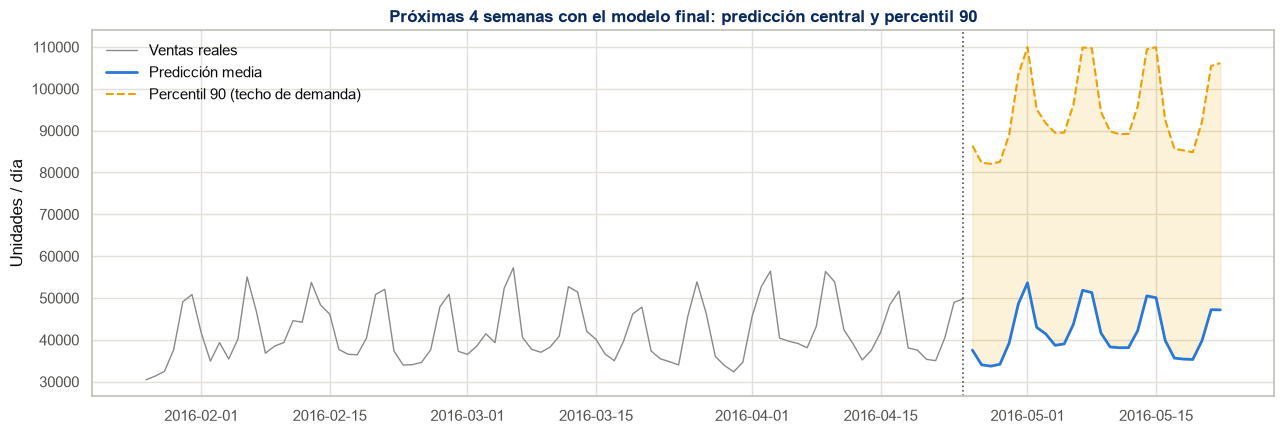

predicciones_28dias.csv: (30490, 29) | total 28 días: 1,169,238 unidades
predicciones_28dias_p90.csv: (30490, 29) | total 28 días: 2,647,580 unidades


In [ ]:
# La entrega: los 28 días siguientes al último día con datos
pred_futuro = np.load(f'{CACHE}/final_futuro_media.npy')
p90_futuro = np.load(f'{CACHE}/final_futuro_p90.npy')
fechas_fut = pd.date_range(fechas_[-1] + pd.Timedelta(days=1), periods=28)
total_hist = pd.Series(V_.sum(axis=0), index=fechas_)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(total_hist.index[-90:], total_hist.values[-90:], color='#8a8a8a', linewidth=1, label='Ventas reales')
ax.plot(fechas_fut, pred_futuro.sum(axis=0), color=DSMARKET_BLUE, linewidth=2, label='Predicción media')
ax.plot(fechas_fut, p90_futuro.sum(axis=0), color=DSMARKET_GOLD, linewidth=1.5, linestyle='--',
        label='Percentil 90 (techo de demanda)')
ax.fill_between(fechas_fut, pred_futuro.sum(axis=0), p90_futuro.sum(axis=0), color=DSMARKET_GOLD, alpha=0.15)
ax.axvline(fechas_[-1], color='#52514e', linestyle=':', linewidth=1.2)
ax.set_title('Próximas 4 semanas con el modelo final: predicción central y percentil 90',
             color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

for nombre, matriz in [('predicciones_28dias.csv', pred_futuro), ('predicciones_28dias_p90.csv', p90_futuro)]:
    salida = pd.DataFrame(matriz, columns=[f'F{i+1}' for i in range(28)])
    salida.insert(0, 'id', meta_['id'].values)
    salida.to_csv(nombre, index=False, float_format='%.4f')
    print(f"{nombre}: {salida.shape} | total 28 días: {matriz.sum():,.0f} unidades")

**Entrega:** predicción de los 28 días siguientes al último dato (25 de abril a 22 de mayo de 2016) para las 30.490 series.

- **Predicción media: 1.169.238 unidades**, muy próxima a lo vendido en las cuatro semanas anteriores (1.183.626). Se mantiene el perfil semanal: picos de unas 50.000 unidades los sábados y domingos y 35.000-40.000 entre semana.
- **Percentil 90: 2.647.580 unidades.** Es el **techo de demanda esperado** de cada producto y día: el nivel que las ventas solo superan 1 de cada 10 días (no el máximo absoluto). No es una previsión de ventas, sino el stock que cubre la demanda el 90 % de los días, y por eso la suma es más del doble que la predicción media.
- Los dos ficheros, `predicciones_28dias.csv` y `predicciones_28dias_p90.csv`, son los que carga el lakehouse (`carga_predicciones.py`) para la aplicación, la API y el panel de Power BI. Utilizan precio arrastrado (sección 11).

## 13. Resumen y paso a la Tarea 4

**Pregunta de Paul.** Sumar las predicciones individuales de tienda-producto es válido y mejora a modelar cada agregado por separado en los cuatro niveles evaluados (sección 7).

**Modelo.** LightGBM global por bloques semanales, entrenado con 400 días, con variables de evento semanal y sin la segmentación de producto (sección 12). WRMSSE de 1,0002 en la última ventana y WAPE semanal del 37,8 %. Con la segmentación como variable el WRMSSE era 0,9994: diferencia de 0,08 %, dentro del ruido de validación (notebook `03b`).

| Decisión | Evidencia |
|---|---|
| Bloques semanales en lugar de un modelo único | Mejora del 2 % con el mismo algoritmo (sección 6) |
| Complejidad del modelo | En el período normal una media móvil por día de la semana queda a entre −0,1 % y 1,5 % del modelo completo; el modelo completo se justifica en temporada alta (secciones 6.1 y 9) |
| 400 días de historia | Diciembre mejora un 5,7 % y noviembre un 3,3 % (sección 9) |
| Eventos semanales | Mejora menor y solo con 400 días (sección 9) |
| Métrica semanal (WAPE) | El error baja del 76 % al 40 % al sumar por semanas (sección 8) |
| Grupo de producto como variable | Sin efecto apreciable: WRMSSE 0,9994 con y 1,0002 sin la variable en la última ventana; igual en las otras cuatro (notebook `03b`) |
| Precios futuros reales | Efecto de 0,04 % en unidades; se conservan ambas versiones (sección 11) |

**Limitaciones.**

1. **Temporada alta.** Con 400 días el modelo aprende el cierre del 25 de diciembre y mejora la subida previa, pero sigue sin captar del todo el pico del 31 de diciembre.
2. **Sesgo.** El modelo subestima un 2 % de media y el factor de corrección no es estable; debe recalcularse en cada reentrenamiento (sección 10).
3. **Demanda irregular.** El error semanal de los grupos de venta esporádica y de pico de diciembre supera el 65 % (sección 8). La simulación del notebook 04 muestra que es donde el modelo aporta más a la reposición pese a su peor RMSSE.

**Entradas a la Tarea 4:** dos números por producto y día (la predicción central y el p90, techo de demanda esperado), utilizados para construir la curva de nivel de servicio frente a capital inmovilizado (pasar del 68 % al 90 % de servicio requiere +127 % de inventario), y políticas distintas por grupo de producto decididas mediante simulación.